# ECON 430: Project I

##  How did stock market volatility in the S&P 500 during the Great Recession compare with volatility in the years leading up to, and following the recession (2000–2014)?
** Note: Discussion of results are included in pdf

#### Yamini Sirobushanam, Livi Gallagher, Zoe Scherrer


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams 

from numpy import random
random.seed(10)

from scipy import stats, optimize
from scipy.stats import norm
from scipy import stats

import statsmodels.api as sm
import statsmodels.stats.api as sms      # NOTE: `sms` always means statsmodels.stats.api
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn import preprocessing, metrics

%matplotlib inline
rcParams['figure.figsize'] = (7, 4.5)
rcParams['figure.dpi'] = 110
pd.set_option('display.width', 120)


import statistics

from pandas import DataFrame as df 
from scipy import io as spio
from scipy import stats

from scipy import misc


%matplotlib inline
warnings.filterwarnings('ignore')

sns.set(style="whitegrid")

/var/folders/hr/nkbk1rws6_jd8451p35rjzlc0000gn/T/ipykernel_12922/2531455024.py:37: DeprecationWarning: scipy.misc is deprecated and will be removed in 2.0.0
  from scipy import misc


## Preprocessing
The preprocessing stage consists of merging 6 different datasets. We used - S&P 500 ( Adj Close), CPI, Unemployment, Consumer Confidence Index, GDP, and the Effective Federal Funds Interest Rate. Given that each variable is measured at various frequences, we applied a datetime command, filtered it across the years 2000 - 2014, and reindexed it so they may be measured at the same frequency (monthly). 

During the EDA phase, GDP, Unemployment rate, and CPI had some issues. GDP and CPI were exhibiting signs of multicollinearity (0.99). To fix this, we decided to measure our GDP by growth rate and applied a percent change transformation on the variable itself, pre indexing. Unemployment rate and the Effective Federal Funds rate were not statistically signifant when we ran our original regression. To fix this, we applied another transformation. Similarly to GDP, we decided to calculate the difference in rates from the previous month to the current month by applying a .diff() function onto our variables. This resulted in our variables being statistically significant. 

We constructed our y variable called volatility. Since we do not have a proper response variable that would measure the exact volatility rate of the stock market, we are using the variable called Adj Close from the S&P 500 dataset. Adj Close is the stock's closing price at the end of each day, reflecting its true value over time. Instead, we used this variable to calculate the daily market returs, then apply a standard deviation function. This allows us to interpret the volatility of the stock market but how far away each closing day value is away from the average. This concluded our preprocessing and EDA section, and we merged it into our final dataframe called full_df. 

In [2]:
#Reading in Files
#Stock = S&P data, CPI = Consumer Price Index, GDP = Gross Domestic Product, Unemployment = Unemployment Rate
#us_econ is the full dataset containing all of our economic indicators

stock = pd.read_csv("SPX.csv.zip")  
cpi = pd.read_csv("cpi_data.csv")
gdp = pd.read_csv("gdp_data.csv")
unemployment = pd.read_csv("unemployment_data.csv")

In [3]:
#Daily trading info 
stock.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23323 entries, 0 to 23322
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       23323 non-null  object 
 1   Open       23323 non-null  float64
 2   High       23323 non-null  float64
 3   Low        23323 non-null  float64
 4   Close      23323 non-null  float64
 5   Adj Close  23323 non-null  float64
 6   Volume     23323 non-null  int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 1.2+ MB


In [4]:
#Measured monthly 

cpi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 601 entries, 0 to 600
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   DATE      601 non-null    object 
 1   CPIAUCSL  601 non-null    float64
dtypes: float64(1), object(1)
memory usage: 9.5+ KB


In [5]:
#Measured quarterly 

gdp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   DATE    201 non-null    object 
 1   GDP     201 non-null    float64
dtypes: float64(1), object(1)
memory usage: 3.3+ KB


In [6]:
#Measured Monthly 

unemployment.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 601 entries, 0 to 600
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   DATE    601 non-null    object 
 1   UNRATE  601 non-null    float64
dtypes: float64(1), object(1)
memory usage: 9.5+ KB


In [7]:
#The variables measure at different frequency, need to convert them to match frequences. 
#Applied datetime function so we can manipulate date and times

stock['Date'] = pd.to_datetime(stock['Date'])
cpi['DATE'] = pd.to_datetime(cpi['DATE'])
gdp['DATE'] = pd.to_datetime(gdp['DATE'])
unemployment['DATE'] = pd.to_datetime(unemployment['DATE'])

In [8]:
#Confirming the years we need are available for each dataset (2000-2014)

print("S&P 500:", stock['Date'].min(), stock['Date'].max())
print("CPI:", cpi['DATE'].min(), cpi['DATE'].max())
print("GDP:", gdp['DATE'].min(), gdp['DATE'].max())
print("Unemployment:", unemployment['DATE'].min(), unemployment['DATE'].max())

S&P 500: 1927-12-30 00:00:00 2020-11-04 00:00:00
CPI: 1974-01-01 00:00:00 2024-01-01 00:00:00
GDP: 1974-01-01 00:00:00 2024-01-01 00:00:00
Unemployment: 1974-01-01 00:00:00 2024-01-01 00:00:00


In [9]:
#Checking for duplicates before beginning merge of cpi, gdp and unemployment

print("Stock duplicates:", stock['Date'].duplicated().sum())
print("CPI duplicates:", cpi['DATE'].duplicated().sum())
print("GDP duplicates:", gdp['DATE'].duplicated().sum())
print("Unemployment duplicates:", unemployment['DATE'].duplicated().sum())

Stock duplicates: 0
CPI duplicates: 0
GDP duplicates: 0
Unemployment duplicates: 0


In [10]:
#Filtering dataset to years 2000-2014

start = '2000-01-01'
end = '2015-01-01'

stock = stock[(stock['Date'] >= start) & (stock['Date'] < end)].copy()
cpi = cpi[(cpi['DATE'] >= start) & (cpi['DATE'] < end)].copy()
gdp = gdp[(gdp['DATE'] >= start) & (gdp['DATE'] < end)].copy()
unemployment = unemployment[
    (unemployment['DATE'] >= start) &
    (unemployment['DATE'] < end)
].copy()

In [11]:
#Post filtering - Checking to make sure it worked

print("S&P 500:", stock['Date'].min(), stock['Date'].max())
print("CPI:", cpi['DATE'].min(), cpi['DATE'].max())
print("GDP:", gdp['DATE'].min(), gdp['DATE'].max())
print("Unemployment:", unemployment['DATE'].min(), unemployment['DATE'].max())

#Checking number of observations
print("\nNumber of observations:")
print("S&P 500:", len(stock))
print("CPI:", len(cpi))
print("GDP:", len(gdp))
print("Unemployment:", len(unemployment))

S&P 500: 2000-01-03 00:00:00 2014-12-31 00:00:00
CPI: 2000-01-01 00:00:00 2014-12-01 00:00:00
GDP: 2000-01-01 00:00:00 2014-10-01 00:00:00
Unemployment: 2000-01-01 00:00:00 2014-12-01 00:00:00

Number of observations:
S&P 500: 3773
CPI: 180
GDP: 60
Unemployment: 180


In [12]:
#Merging the unemployment, cpi
#how = inner: merging the rows that have identical values 

us_econ = pd.merge(cpi, unemployment, on='DATE', how = 'inner')

In [13]:
us_econ.head(10)
us_econ.shape

(180, 3)

In [14]:
#Checking for missing values

us_econ.isnull().sum()

DATE        0
CPIAUCSL    0
UNRATE      0
dtype: int64

In [15]:
#Checking for duplicate values

us_econ.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
175    False
176    False
177    False
178    False
179    False
Length: 180, dtype: bool

In [16]:
#merging gdp to us_econ: since it measured quarterly, creating identifier to align it with monthly observations
#resampling - fills in the missing month values with each quarter of the month value
#During the original regression analysis, GDP and CPI had a correlation of 0.99 (near perfect multicollinearity). Applied this transformation in the preprocessing process to fix this

gdp = gdp.sort_values('DATE')

gdp['GDP_Growth'] = gdp['GDP'].pct_change() * 100

gdp_monthly = gdp.set_index('DATE').resample('MS').ffill().reset_index()
gdp_monthly.head()

,DATE,GDP,GDP_Growth
0,2000-01-01,10002.179,NaN
1,2000-02-01,10002.179,NaN
2,2000-03-01,10002.179,NaN
3,2000-04-01,10247.720,2.454875
4,2000-05-01,10247.720,2.454875


In [17]:
#Output after filtering out the date ranges, GDP: 2000-01-01 00:00:00 2014-10-01 00:00:00, not extending the dates since it will not affect our estimation too much

gdp_monthly = (gdp_monthly.set_index('DATE').reindex(pd.date_range('2000-01-01', '2014-12-01', freq='MS')).ffill().rename_axis('DATE').reset_index())
gdp_monthly.tail()

,DATE,GDP,GDP_Growth
175,2014-08-01,17804.228,1.630961
176,2014-09-01,17804.228,1.630961
177,2014-10-01,17912.079,0.605761
178,2014-11-01,17912.079,0.605761
179,2014-12-01,17912.079,0.605761


In [18]:
#merging gdp_monthly with us_econ
# how = left: joing everything irregardless of match

us_econ = pd.merge(us_econ, gdp_monthly, on='DATE', how = 'left')

In [19]:
us_econ[['DATE', 'GDP', 'GDP_Growth']].head()

,DATE,GDP,GDP_Growth
0,2000-01-01,10002.179,NaN
1,2000-02-01,10002.179,NaN
2,2000-03-01,10002.179,NaN
3,2000-04-01,10247.720,2.454875
4,2000-05-01,10247.720,2.454875


### Constructing the Y Variable

Measuring volatility as the standard deviation of daily S&P returns within each month (adj close). 

1. Calculate daily stock market returns

2. Calculate the sd of those returns for each month
	 


In [20]:
#copying df, all changes will happen to stock_returns

stock_returns = stock.copy()

In [21]:
stock_returns = stock_returns.sort_values('Date')

In [22]:
stock_returns.head()

,Date,Open,High,Low,Close,Adj Close,Volume
18078,2000-01-03,1469.250000,1478.000000,1438.359985,1455.219971,1455.219971,931800000
18079,2000-01-04,1455.219971,1455.219971,1397.430054,1399.420044,1399.420044,1009000000
18080,2000-01-05,1399.420044,1413.270020,1377.680054,1402.109985,1402.109985,1085500000
18081,2000-01-06,1402.109985,1411.900024,1392.099976,1403.449951,1403.449951,1092300000
18082,2000-01-07,1403.449951,1441.469971,1400.729980,1441.469971,1441.469971,1225200000


In [23]:
#Daily stock market returns

stock_returns['Daily_returns'] = stock_returns['Adj Close'].pct_change() * 100
stock_returns[['Date', 'Adj Close', 'Daily_returns']].head()

#Apparently calculating the sd leaves out missing values, so I did not need to drop additional missing values 

,Date,Adj Close,Daily_returns
18078,2000-01-03,1455.219971,NaN
18079,2000-01-04,1399.420044,-3.834467
18080,2000-01-05,1402.109985,0.192218
18081,2000-01-06,1403.449951,0.095568
18082,2000-01-07,1441.469971,2.709040


In [24]:
#Creating a monthly identifier to match the frequency of the other variables
#Every 3 months will have the same value

stock_returns['Month'] = stock_returns['Date'].dt.to_period('M')
stock_returns[['Date', 'Daily_returns', 'Month']].head()

,Date,Daily_returns,Month
18078,2000-01-03,NaN,2000-01
18079,2000-01-04,-3.834467,2000-01
18080,2000-01-05,0.192218,2000-01
18081,2000-01-06,0.095568,2000-01
18082,2000-01-07,2.709040,2000-01


In [25]:
#Calculating sd for each month

monthly_volatility = (stock_returns.groupby('Month')['Daily_returns'].std().reset_index(name='volatility'))

In [26]:
print(monthly_volatility.shape)
print(monthly_volatility.isnull().sum())
monthly_volatility.head(10)

(180, 2)
Month         0
volatility    0
dtype: int64


,Month,volatility
0,2000-01,1.671759
1,2000-02,1.252883
2,2000-03,1.689696
3,2000-04,2.095314
4,2000-05,1.568744
5,2000-06,1.053733
6,2000-07,1.039614
7,2000-08,0.634470
8,2000-09,0.874582
9,2000-10,1.628320


In [27]:
#Merging new df with the other datasets, converting to datetime
#Monthly_volatility is showing month/year where as us_econ shows month, date and year

monthly_volatility['DATE'] = monthly_volatility['Month'].dt.to_timestamp()
monthly_volatility[['Month', 'DATE']].head()

,Month,DATE
0,2000-01,2000-01-01
1,2000-02,2000-02-01
2,2000-03,2000-03-01
3,2000-04,2000-04-01
4,2000-05,2000-05-01


In [28]:
#Federal interest rate

federal_interest = pd.read_csv("index.csv")

In [29]:
#We are only using effective federal funds rate, will drop everything but date and that column

federal_interest.head()

,Year,Month,Day,Federal Funds Target Rate,Federal Funds Upper Target,Federal Funds Lower Target,Effective Federal Funds Rate,Real GDP (Percent Change),Unemployment Rate,Inflation Rate
0,1954,7,1,NaN,NaN,NaN,0.80,4.6,5.8,NaN
1,1954,8,1,NaN,NaN,NaN,1.22,NaN,6.0,NaN
2,1954,9,1,NaN,NaN,NaN,1.06,NaN,6.1,NaN
3,1954,10,1,NaN,NaN,NaN,0.85,8.0,5.7,NaN
4,1954,11,1,NaN,NaN,NaN,0.83,NaN,5.3,NaN


In [30]:
#Combining year, month and day into one column

federal_interest['DATE'] = pd.to_datetime(federal_interest[['Year', 'Month', 'Day']])

In [31]:
#Keeping only relevant columns

federal_interest = federal_interest[ ['DATE', 'Effective Federal Funds Rate']].copy()
federal_interest.head()

,DATE,Effective Federal Funds Rate
0,1954-07-01,0.80
1,1954-08-01,1.22
2,1954-09-01,1.06
3,1954-10-01,0.85
4,1954-11-01,0.83


In [32]:
#Consumer confidence index

cci = pd.read_csv("DP_LIVE_21012022073653464.csv (1).zip")

In [33]:
cci.head()

,LOCATION,INDICATOR,SUBJECT,MEASURE,FREQUENCY,TIME,Value,Flag Codes
0,NLD,CCI,AMPLITUD,LTRENDIDX,M,1973-01,101.5028,NaN
1,NLD,CCI,AMPLITUD,LTRENDIDX,M,1973-02,101.4815,NaN
2,NLD,CCI,AMPLITUD,LTRENDIDX,M,1973-03,101.3081,NaN
3,NLD,CCI,AMPLITUD,LTRENDIDX,M,1973-04,101.0173,NaN
4,NLD,CCI,AMPLITUD,LTRENDIDX,M,1973-05,100.8456,NaN


In [34]:
cci.tail()

,LOCATION,INDICATOR,SUBJECT,MEASURE,FREQUENCY,TIME,Value,Flag Codes
18221,CRI,CCI,AMPLITUD,LTRENDIDX,M,2021-07,98.93296,NaN
18222,CRI,CCI,AMPLITUD,LTRENDIDX,M,2021-08,99.29540,NaN
18223,CRI,CCI,AMPLITUD,LTRENDIDX,M,2021-09,99.49060,NaN
18224,CRI,CCI,AMPLITUD,LTRENDIDX,M,2021-10,99.57128,NaN
18225,CRI,CCI,AMPLITUD,LTRENDIDX,M,2021-11,99.61041,NaN


In [35]:
#Keeping all rows that equal US, since this dataset consists of multiple countries

cci = cci[cci['LOCATION'] == 'USA'].copy()

In [36]:
cci.head()

,LOCATION,INDICATOR,SUBJECT,MEASURE,FREQUENCY,TIME,Value,Flag Codes
6152,USA,CCI,AMPLITUD,LTRENDIDX,M,1960-01,101.6820,NaN
6153,USA,CCI,AMPLITUD,LTRENDIDX,M,1960-02,101.4006,NaN
6154,USA,CCI,AMPLITUD,LTRENDIDX,M,1960-03,101.1575,NaN
6155,USA,CCI,AMPLITUD,LTRENDIDX,M,1960-04,101.0234,NaN
6156,USA,CCI,AMPLITUD,LTRENDIDX,M,1960-05,101.0573,NaN


In [37]:
cci.shape

(744, 8)

In [38]:
#Verifying the filtering to USA worked

cci['LOCATION'].unique()

array(['USA'], dtype=object)

In [39]:
cci['DATE'] = pd.to_datetime(cci['TIME'])

In [40]:
cci['DATE'].duplicated().sum()

np.int64(0)

In [41]:
#Keeping value and date column: 

cci = cci[['DATE', 'Value']].copy()

In [42]:
#Renaming value to cci

cci = cci.rename(columns={'Value': 'CCI'})

In [43]:
cci.head()

,DATE,CCI
6152,1960-01-01,101.6820
6153,1960-02-01,101.4006
6154,1960-03-01,101.1575
6155,1960-04-01,101.0234
6156,1960-05-01,101.0573


In [44]:
#2000-2014 filtering for the rest of the variables (federal interest and cci)

start = '2000-01-01'
end = '2015-01-01'

federal_interest = federal_interest[(federal_interest['DATE'] >= start) & (federal_interest['DATE'] < end)].copy()
cci = cci[(cci['DATE'] >= start) & (cci['DATE'] < end)].copy()

In [45]:
#Verifying the filtering worked

print("federal_interest:", federal_interest['DATE'].min(), federal_interest['DATE'].max())
print("cci:", cci['DATE'].min(), cci['DATE'].max())

federal_interest: 2000-01-01 00:00:00 2014-12-01 00:00:00
cci: 2000-01-01 00:00:00 2014-12-01 00:00:00


In [46]:
#Verifying # of observations

print("stock:", stock.shape)
print("CPI:", cpi.shape)
print("GDP:", gdp.shape)
print("Unemployment:", unemployment.shape)
print("Federal Interest Rate:", federal_interest.shape)
print("Consumer Confidence Interval:", cci.shape)

stock: (3773, 7)
CPI: (180, 2)
GDP: (60, 3)
Unemployment: (180, 2)
Federal Interest Rate: (222, 2)
Consumer Confidence Interval: (180, 2)


In [47]:
#There are 222 obs which is inconsistent with the rest aside from gdp

federal_interest.duplicated().sum()

np.int64(0)

In [48]:
federal_interest['DATE'].min()

Timestamp('2000-01-01 00:00:00')

In [49]:
federal_interest['DATE'].max()

Timestamp('2014-12-01 00:00:00')

In [50]:
federal_interest.isnull().sum()

DATE                             0
Effective Federal Funds Rate    42
dtype: int64

In [51]:
#Number of obs are now matching across all datasets after dropping the missing values

federal_interest = federal_interest.dropna().copy()
federal_interest.shape

(180, 2)

#### Final Merging

In [52]:
us_econ = pd.merge(us_econ, federal_interest,on='DATE', how = 'left')

In [53]:
us_econ.head()

,DATE,CPIAUCSL,UNRATE,GDP,GDP_Growth,Effective Federal Funds Rate
0,2000-01-01,169.3,4.0,10002.179,NaN,5.45
1,2000-02-01,170.0,4.1,10002.179,NaN,5.73
2,2000-03-01,171.0,4.0,10002.179,NaN,5.85
3,2000-04-01,170.9,3.8,10247.720,2.454875,6.02
4,2000-05-01,171.2,4.0,10247.720,2.454875,6.27


In [54]:
us_econ = pd.merge(us_econ, cci ,on='DATE', how = 'left')

In [55]:
us_econ.head()

,DATE,CPIAUCSL,UNRATE,GDP,GDP_Growth,Effective Federal Funds Rate,CCI
0,2000-01-01,169.3,4.0,10002.179,NaN,5.45,102.9514
1,2000-02-01,170.0,4.1,10002.179,NaN,5.73,103.0087
2,2000-03-01,171.0,4.0,10002.179,NaN,5.85,102.9210
3,2000-04-01,170.9,3.8,10247.720,2.454875,6.02,102.9009
4,2000-05-01,171.2,4.0,10247.720,2.454875,6.27,102.8735


In [56]:
us_econ.shape

(180, 7)

In [57]:
us_econ.isnull().sum()

DATE                            0
CPIAUCSL                        0
UNRATE                          0
GDP                             0
GDP_Growth                      3
Effective Federal Funds Rate    0
CCI                             0
dtype: int64

In [58]:
us_econ.duplicated().sum()

np.int64(0)

In [59]:
#Merging economic data with volatility

full_df = pd.merge(us_econ, monthly_volatility[['DATE', 'volatility']], on='DATE', how='left')

#Dropping original GDP
full_df = full_df.drop(columns=['GDP'])

#Sort by date
full_df = full_df.sort_values('DATE')

#Calculate monthly changes
#Original regression revealed that both variables were statistically insiginficant
#.diff() transformation is calculating the difference in previous month vs current month. Is still being interpreted as percentage points.

full_df['UNRATE_Change'] = full_df['UNRATE'].diff()
full_df['FedFunds_Change'] = full_df['Effective Federal Funds Rate'].diff()

#Dropping original unemployment and federal funds rate levels
full_df = full_df.drop(columns=['UNRATE', 'Effective Federal Funds Rate'])

#Remove missing observations
full_df = full_df.dropna().reset_index(drop=True)

#Check dataset
full_df.head()

,DATE,CPIAUCSL,GDP_Growth,CCI,volatility,UNRATE_Change,FedFunds_Change
0,2000-04-01,170.9,2.454875,102.9009,2.095314,-0.2,0.17
1,2000-05-01,171.2,2.454875,102.8735,1.568744,0.2,0.25
2,2000-06-01,172.2,2.454875,102.7664,1.053733,0.0,0.26
3,2000-07-01,172.7,0.687421,102.7301,1.039614,0.0,0.01
4,2000-08-01,172.7,0.687421,102.6923,0.634470,0.1,-0.04


In [60]:
full_df.shape

(177, 7)

In [61]:
#Verifying that our GDP transformation to growth rate fixed the near perfect multicollinearity

full_df[['CPIAUCSL', 'GDP_Growth']].corr()

,CPIAUCSL,GDP_Growth
CPIAUCSL,1.000000,-0.175394
GDP_Growth,-0.175394,1.000000


## Data Description and Exploratory  Analysis

In [62]:
#Basic summary

print(full_df.describe())
full_df_skew = stats.skew(full_df["volatility"])
full_df_kurt = stats.kurtosis(full_df["volatility"])

print(f'skew\t {full_df_skew:.5f}')
print(f'kurtosis {full_df_kurt:.6f}')

                                DATE    CPIAUCSL  GDP_Growth         CCI  volatility  UNRATE_Change  FedFunds_Change
count                            177  177.000000  177.000000  177.000000  177.000000     177.000000       177.000000
mean   2007-08-01 12:12:12.203389952  205.811757    0.995238   99.429019    1.092099       0.009040        -0.032373
min              2000-04-01 00:00:00  170.900000   -1.951742   96.364550    0.257277      -0.500000        -0.960000
25%              2003-12-01 00:00:00  185.500000    0.618142   98.329530    0.644672      -0.100000        -0.020000
50%              2007-08-01 00:00:00  207.667000    1.134364   99.549890    0.946509       0.000000         0.000000
75%              2011-04-01 00:00:00  224.093000    1.400572  100.527800    1.235962       0.100000         0.020000
max              2014-12-01 00:00:00  237.498000    2.454875  102.900900    5.090923       0.500000         0.260000
std                              NaN   20.535972    0.746955    

Monthly volatility is measured as the standard deviation of daily S&P 500 percentage returns within each month. 

- Mean: 1.092: Average monthly measure of daily return volatility is approximately 1.09%
  
- SD: 0.689. Monthly volatility levels vary around 0.689 percentage points away from the mean

  
- Max: 5.091: One month experienced an exceptionally high daily return

- Min: 0.947: median is below the mean, unusually high volatility could be pulling mean upwards.

In [63]:
print(type(stats))

<class 'module'>


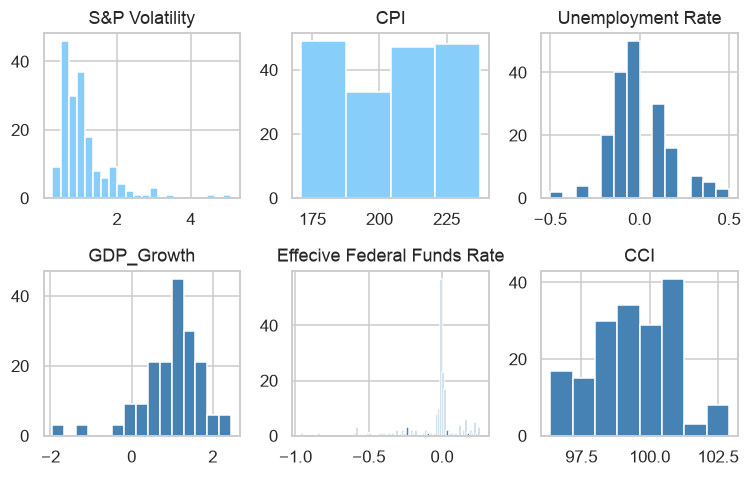

In [64]:
#Freedman and Diaconis Histogram

x1 = full_df['volatility']
x2 = full_df['CPIAUCSL']
x3 = full_df['UNRATE_Change']
x4 = full_df['GDP_Growth']
x5 = full_df['FedFunds_Change']
x6 = full_df['CCI']
n = len(x1)

fd_x1 = int(0.5 * (n**(1/3) * (max(x1) - min(x1))) /(np.quantile(x1, 0.75) - np.quantile(x1, 0.25)))
fd_x2 = int(0.5 * (n**(1/3) * (max(x2) - min(x2))) /(np.quantile(x2, 0.75) - np.quantile(x2, 0.25)))
fd_x3 = int(0.5 * (n**(1/3) * (max(x3) - min(x3))) /(np.quantile(x3, 0.75) - np.quantile(x3, 0.25)))
fd_x4 = int(0.5 * (n**(1/3) * (max(x4) - min(x4))) /(np.quantile(x4, 0.75) - np.quantile(x4, 0.25)))
fd_x5 = int(0.5 * (n**(1/3) * (max(x5) - min(x5))) /(np.quantile(x5, 0.75) - np.quantile(x5, 0.25)))
fd_x6 = int(0.5 * (n**(1/3) * (max(x6) - min(x6))) /(np.quantile(x6, 0.75) - np.quantile(x6, 0.25)))

fig1, ax1 = plt.subplots(2, 3)
ax1[0,0].hist(x1, bins=fd_x1, color='lightskyblue')
ax1[0,0].set_title('S&P Volatility')

ax1[0,1].hist(x2, bins=fd_x2, color='lightskyblue')
ax1[0,1].set_title('CPI')

ax1[0,2].hist(x3, bins=fd_x3, color='steelblue')
ax1[0,2].set_title('Unemployment Rate')

ax1[1,0].hist(x4, bins=fd_x4, color='steelblue')
ax1[1,0].set_title('GDP_Growth')

ax1[1,1].hist(x5, bins=fd_x5, color='steelblue')
ax1[1,1].set_title('Effecive Federal Funds Rate')

ax1[1,2].hist(x6, bins=fd_x6, color='steelblue')
ax1[1,2].set_title('CCI')

plt.tight_layout()
plt.show()



S&P: Right skewed. Most months seem to have low volatility, but other exhibit a significant increase in volatility. Consistent with our previous summary stat. Skewness = 2.577 and kurtosis = 9.367

CPI: Relatively spread out. Nothing abnormal stands out here

Unemployment: Distribution is centered around 0. Some months indicate that unemployment rate was relatively small while others are larger. Consistent with our median monthly change being 0

GDP: Most observations are clusteres between 0 and 2%. This historgram does not represent 177 independent quarterly growth observatoin, so GDP growth will be repeated across months. Left tail correlates with the argument that the Great Recession lowered GDP. 

Federal Funds Rate: Distribution is large. Some months experienced substantial rate cuts but for the most part relatively unchanged. 

CCI: Concentrated around 98-101. Distribution is uneven

In [65]:
#Boxplots: NBER reports Prerecession = 01/2000-11/2007, Great Recession 12/2007-06/2009, Post 06/2009 - 12/2014

full_df['Period'] = 'Pre-Recession'

full_df.loc[(full_df['DATE'] >= '2007-12-01') & (full_df['DATE'] <= '2009-06-01'), 'Period'] = 'Great Recession'

full_df.loc[full_df['DATE'] >= '2009-07-01', 'Period'] = 'Post-Recession'


In [66]:
def scale(a):
    b = (a-a.min())/(a.max()-a.min())
    return b

data_scale = full_df.copy()
data_scale ['volatility'] = scale(data_scale['volatility'])

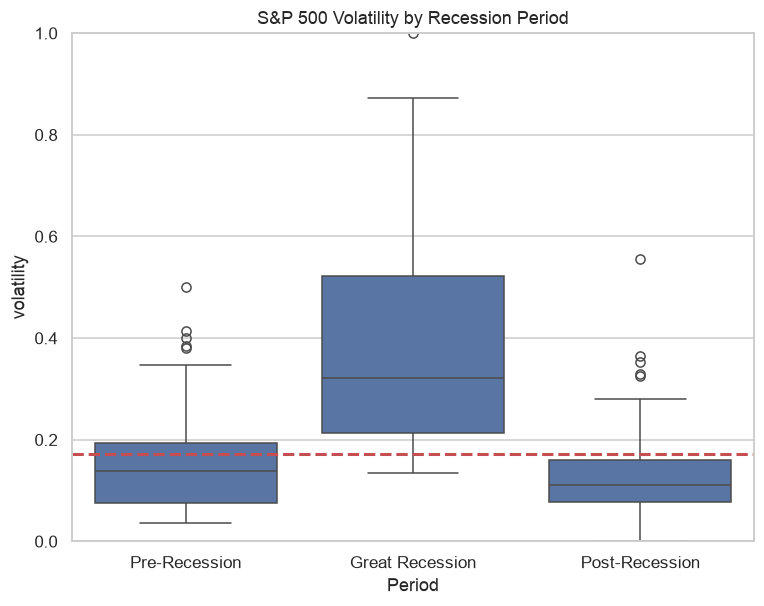

In [67]:
var = 'Period'
data_plt = pd.concat([data_scale['volatility'], data_scale[var]], axis=1)
f, ax = plt.subplots(figsize=(8, 6))
fig = sns.boxplot(x=var, y="volatility", data=data_plt, order = ['Pre-Recession', 'Great Recession', 'Post-Recession'])
fig.axis(ymin=0, ymax=1)
plt.axhline(data_scale.volatility.mean(),color='r',linestyle='dashed',linewidth=2)

plt.title('S&P 500 Volatility by Recession Period')
plt.show()

#variable names are interchangable to produce other charts

                 volatility  CPIAUCSL  GDP_Growth  UNRATE_Change  FedFunds_Change       CCI
volatility         1.000000 -0.107786   -0.618318       0.384351        -0.457141 -0.373179
CPIAUCSL          -0.107786  1.000000   -0.175394      -0.158403         0.075121 -0.661186
GDP_Growth        -0.618318 -0.175394    1.000000      -0.512091         0.488102  0.510073
UNRATE_Change      0.384351 -0.158403   -0.512091       1.000000        -0.267152 -0.241303
FedFunds_Change   -0.457141  0.075121    0.488102      -0.267152         1.000000  0.226083
CCI               -0.373179 -0.661186    0.510073      -0.241303         0.226083  1.000000


<Axes: >

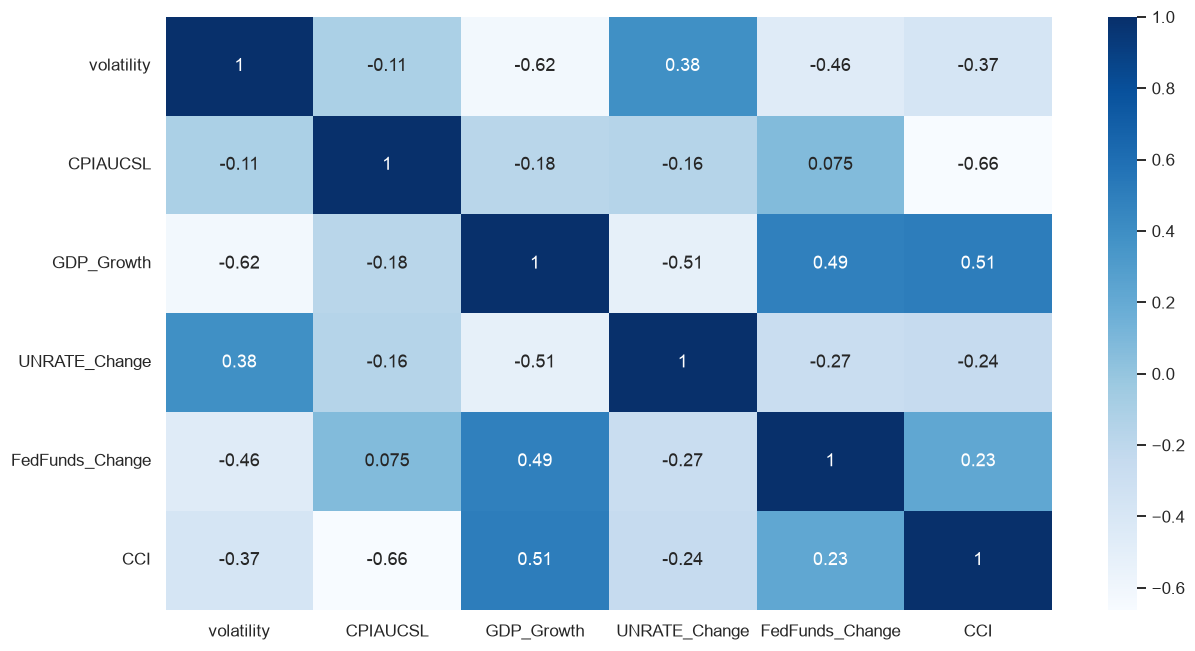

In [68]:
#Correlation Heatmap

plt.figure(figsize=(13,7))
c=full_df[['volatility', 'CPIAUCSL', 'GDP_Growth', 'UNRATE_Change', 'FedFunds_Change',
       'CCI']].corr()
print(c)
sns.heatmap(c,annot=True, cmap="Blues")

#Multicollin b/w CPI and GDP, unemployment and federal funds, solved with our transformation
#Currently reflects all changed variables (GDP_growth, UNRATE_Change, FedFunds_Change). 

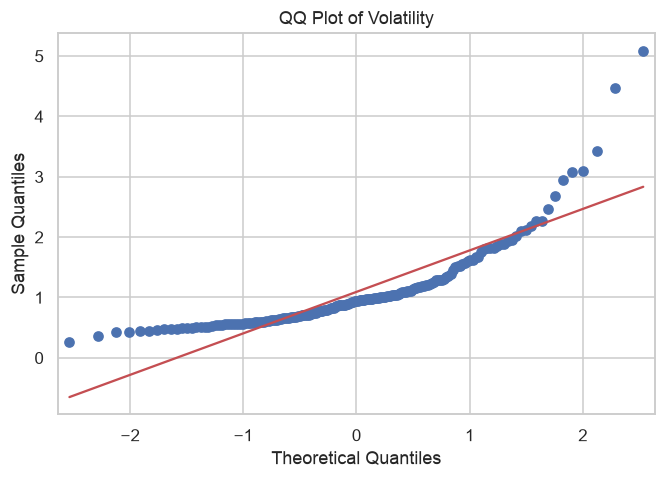

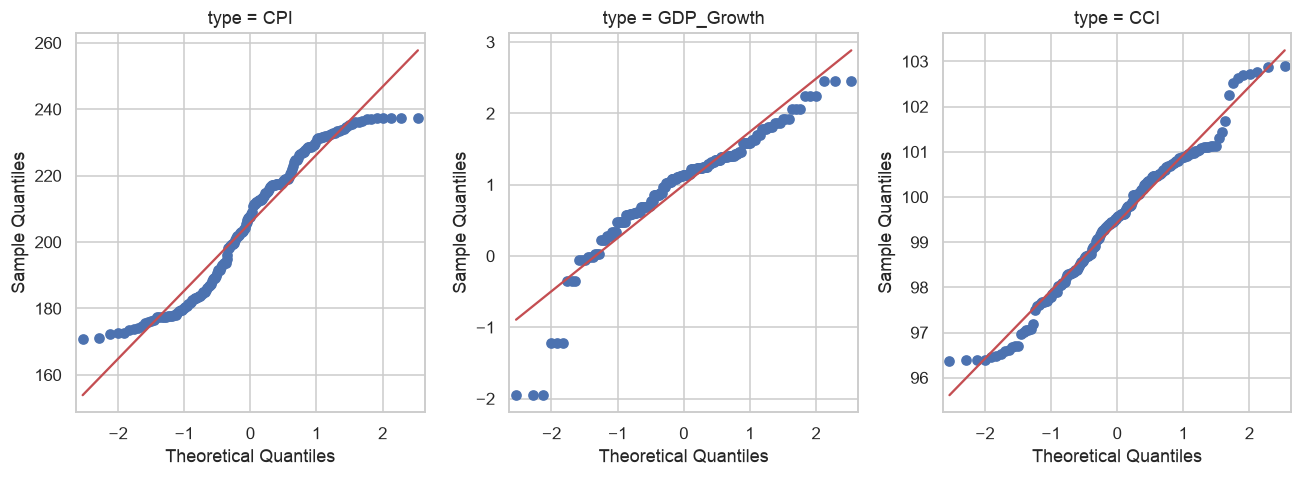

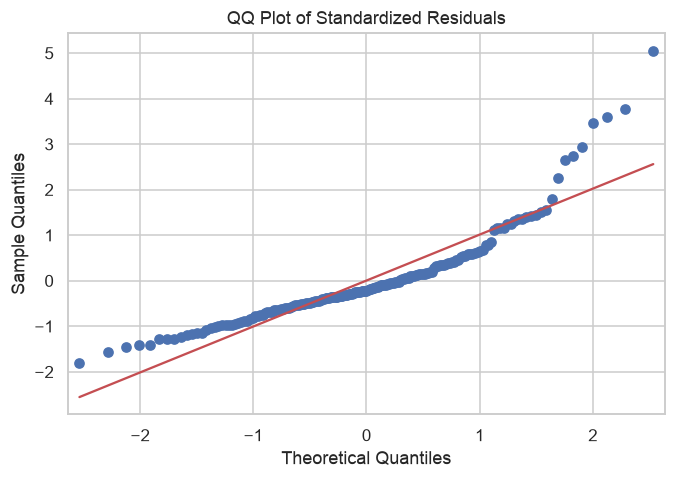

In [69]:
#QQ Plots

sm.qqplot(full_df['volatility'].dropna(), line='s')
plt.title('QQ Plot of Volatility')
plt.show()

# By type: CPIAUCSL, UNRATE, GDP, Effective Federal Funds Rate, CCI
fig2, ax2 = plt.subplots(1, 3, figsize=(4*3, 1.5*3))

sm.qqplot(full_df['CPIAUCSL'].dropna(), line='s', ax=ax2[0])
ax2[0].set_title('type = CPI')

sm.qqplot(full_df['GDP_Growth'].dropna(), line='s', ax=ax2[1])
ax2[1].set_title('type = GDP_Growth')

sm.qqplot(full_df['CCI'].dropna(), line='s', ax=ax2[2])
ax2[2].set_title('type = CCI')

plt.tight_layout()
plt.show()

# Of OLS residuals
full_df_ols_fit = smf.ols('volatility ~ CPIAUCSL + GDP_Growth + CCI',data=full_df).fit()

full_df_ols_influence = full_df_ols_fit.get_influence()
full_df_ols_std_resid = full_df_ols_influence.resid_studentized_internal # standardized residual

sm.qqplot(full_df_ols_std_resid, line='s')
plt.title('QQ Plot of Standardized Residuals')
plt.show()

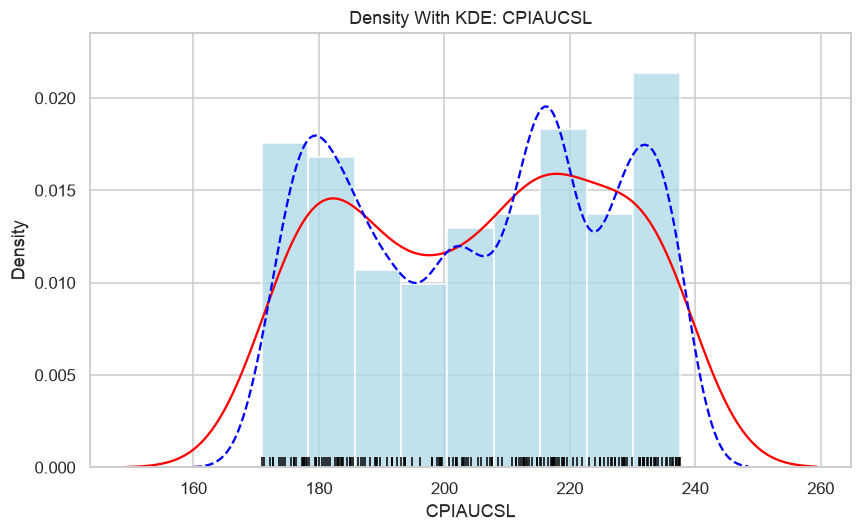

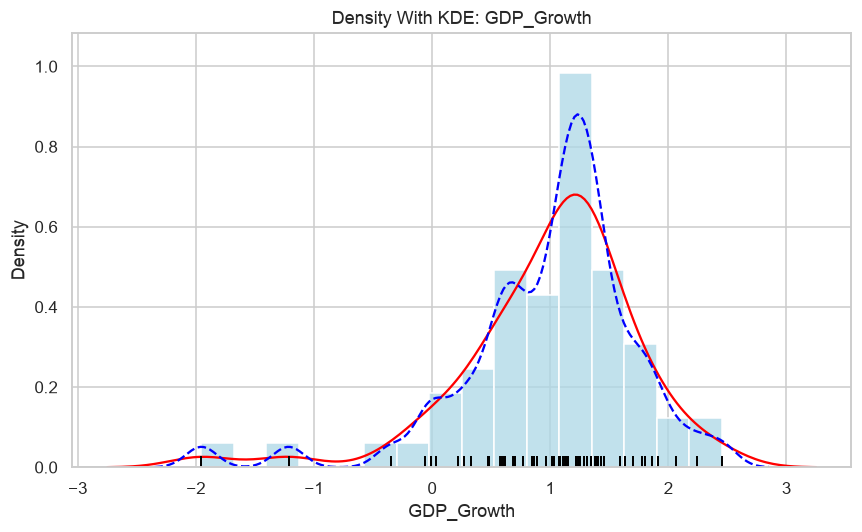

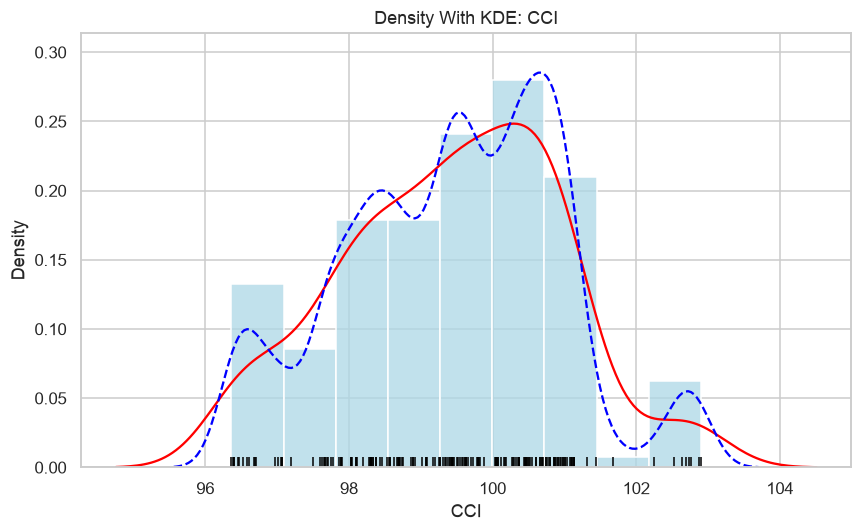

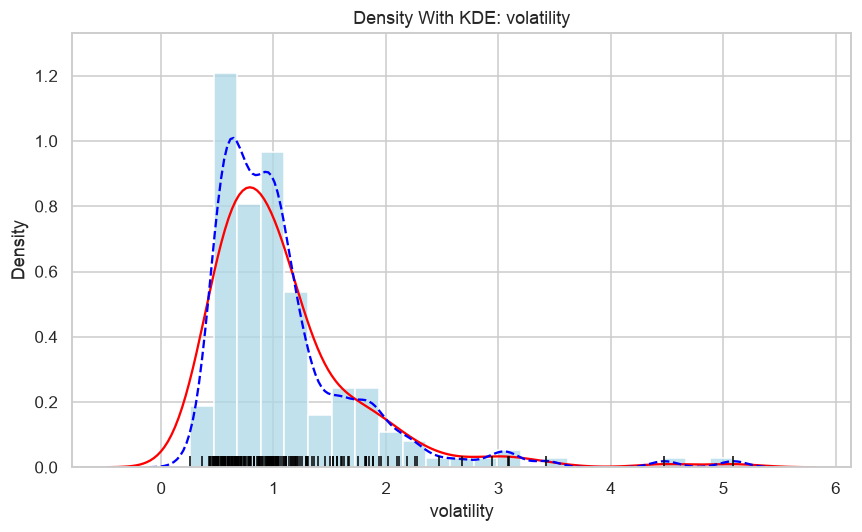

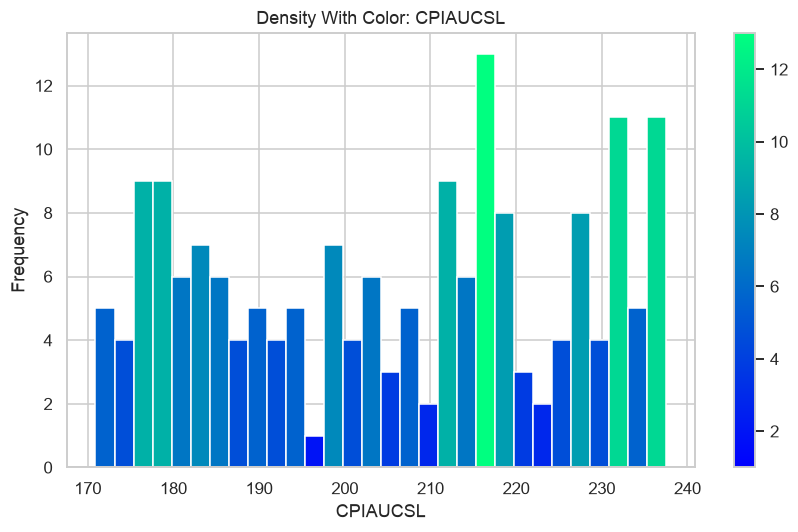

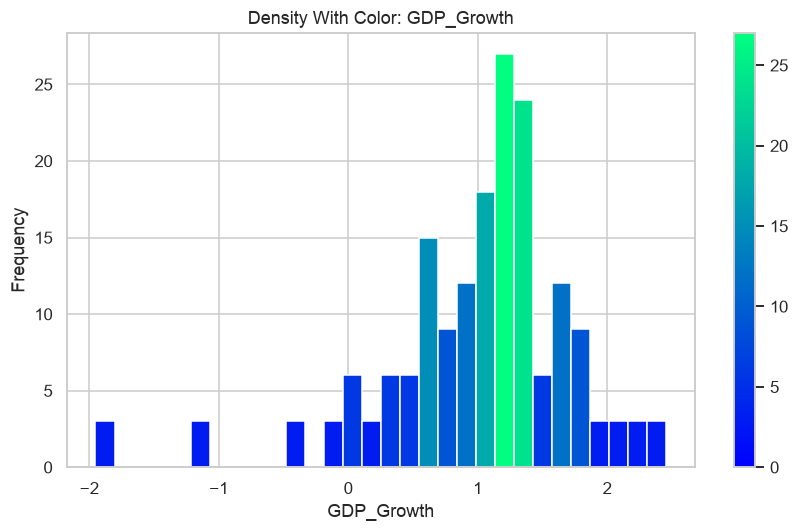

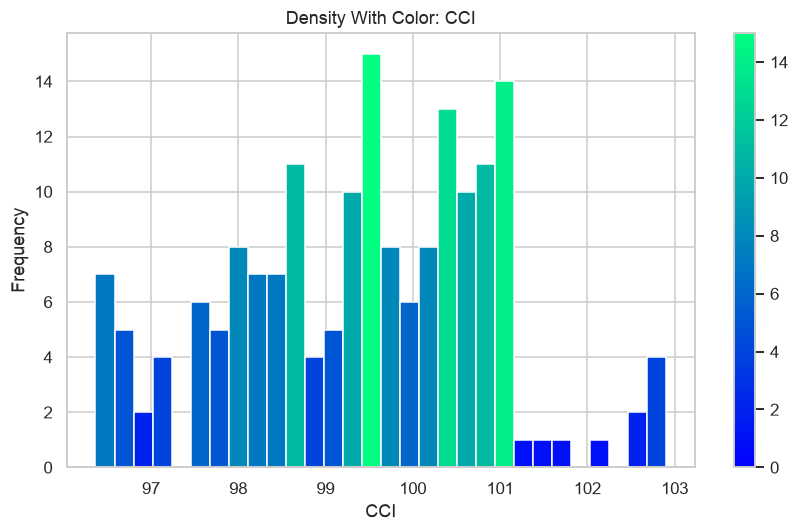

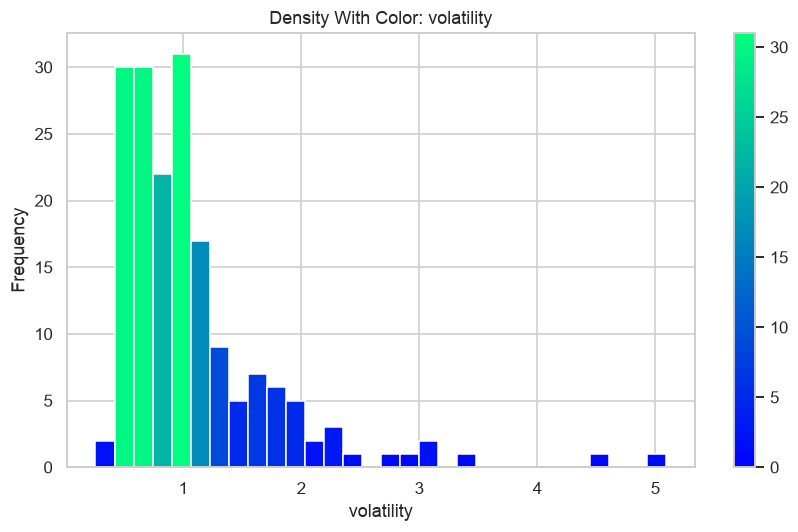

In [70]:
#Density Plots

variables = ['CPIAUCSL', 'GDP_Growth','CCI', 'volatility']

for var in variables:
    data = full_df[var].dropna()

    plt.figure(figsize=(8, 5))
    sns.histplot(data, kde=False, stat='density', color='lightblue')
    sns.kdeplot(data, color='red')
    sns.kdeplot(data, bw_adjust=0.5, color='blue', linestyle='--')   # less smooth
    sns.rugplot(data, color='black')                                 
    plt.title(f'Density With KDE: {var}')
    plt.xlabel(var)
    plt.ylabel('Density')
    plt.tight_layout()
    plt.show()

for var in variables:
    data = full_df[var].dropna()

    plt.figure(figsize=(8, 5))

    # Histogram (about 30 bins, scaled to each variable's range)
    bw = (data.max() - data.min()) / 30
    n, bins, patches = plt.hist(data, bins=np.arange(data.min(), data.max() + bw, bw))

    max_height = max(n)
    for rect, count in zip(patches, n):
        color = plt.cm.winter(count / max_height)
        rect.set_facecolor(color)

    cbar = plt.cm.ScalarMappable(cmap='winter')
    cbar.set_array(n)
    plt.colorbar(cbar, ax=plt.gca())

    plt.xlabel(var)
    plt.ylabel('Frequency')
    plt.title(f'Density With Color: {var}')
    plt.tight_layout()
    plt.show()

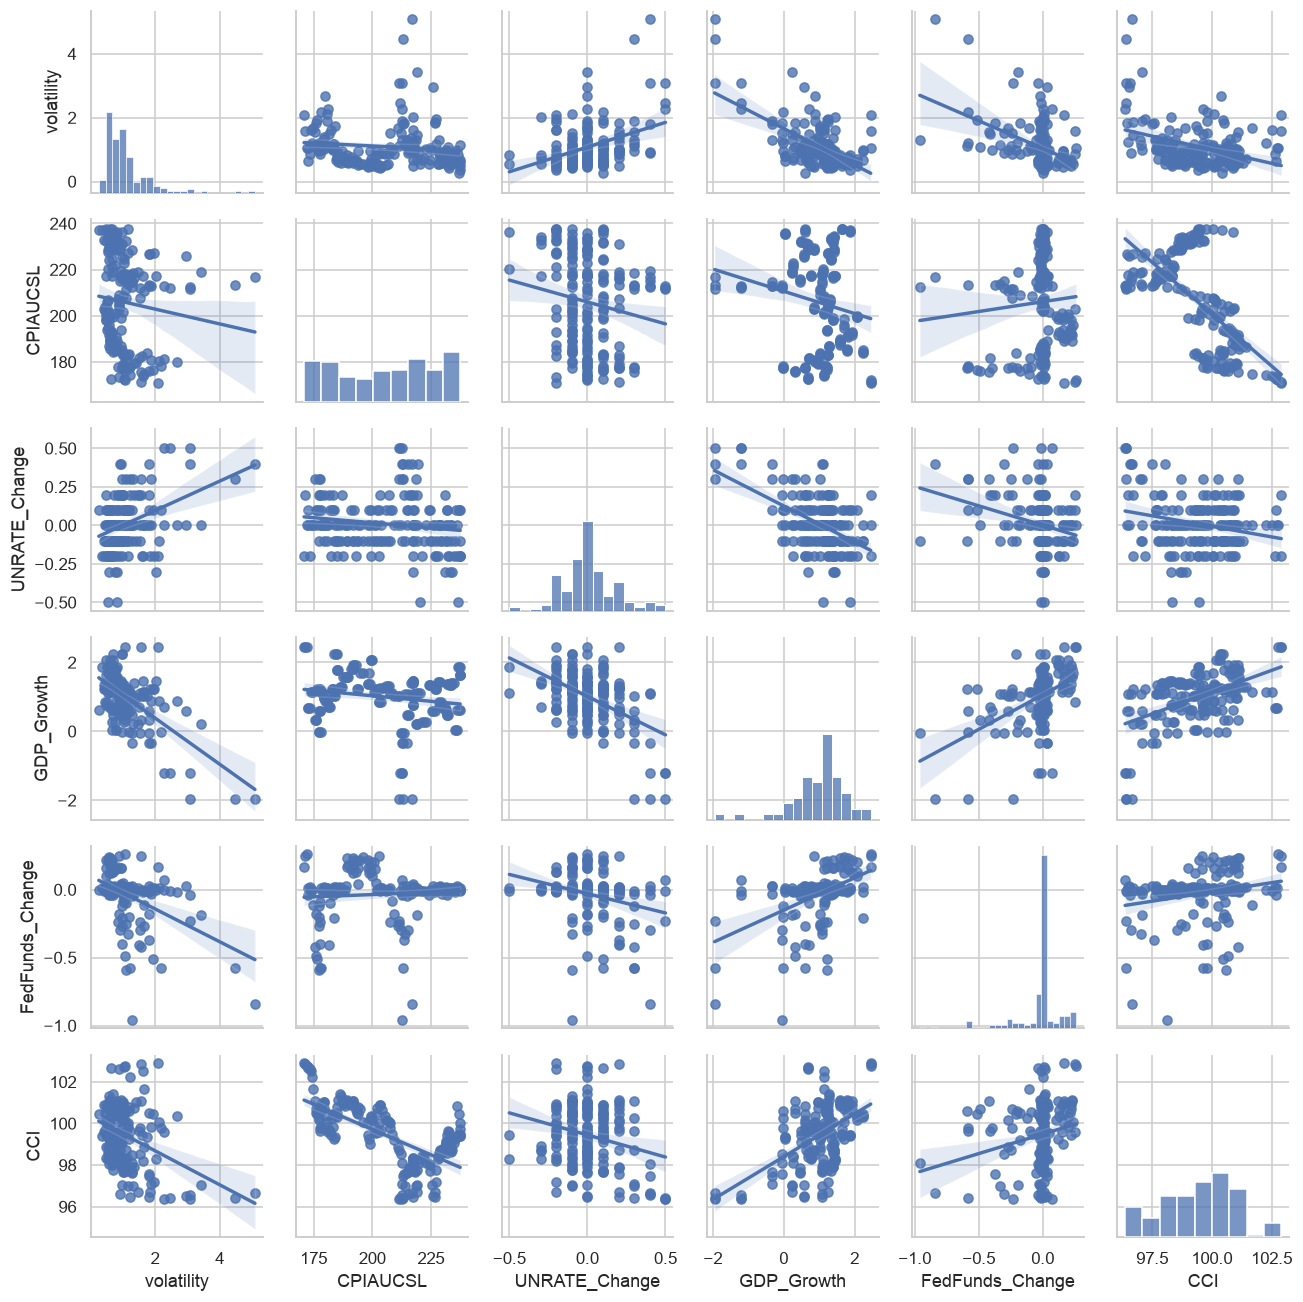

In [71]:
#Scatterplot Matrix

warnings.filterwarnings("ignore", category=UserWarning, module="seaborn")

sns.pairplot(full_df[['volatility', 'CPIAUCSL', 'UNRATE_Change', 'GDP_Growth', 'FedFunds_Change', 'CCI']],kind='reg', height=2)
plt.tight_layout()

In [72]:
#IQR for outliers

Q1 = full_df['volatility'].quantile(0.25)
Q3 = full_df['volatility'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = full_df[(full_df['volatility'] < lower_bound) |(full_df['volatility'] > upper_bound)]

print(outliers[['DATE', 'volatility']])
print("Number of outliers:", len(outliers))

          DATE  volatility
17  2001-09-01    2.191430
27  2002-07-01    2.681257
30  2002-10-01    2.261240
101 2008-09-01    3.426061
102 2008-10-01    5.090923
103 2008-11-01    4.476468
104 2008-12-01    3.091874
105 2009-01-01    2.473262
106 2009-02-01    2.274000
107 2009-03-01    3.084508
136 2011-08-01    2.947953
Number of outliers: 11


In [118]:
#Standardized Residuals

# Calculate Z-scores for volatility
full_df['volatility_zscore'] = ((full_df['volatility'] - full_df['volatility'].mean()) / full_df['volatility'].std())

#Summary stats

print(full_df['volatility_zscore'].describe())

#outliers
outliers_std = full_df[full_df['volatility_zscore'].abs() > 2]

print("\nPotential Outliers:")
print(outliers_std[['DATE', 'volatility', 'volatility_zscore']])

print("\nNumber of potential outliers:", len(outliers_std))

count    1.770000e+02
mean     3.010774e-17
std      1.000000e+00
min     -1.211508e+00
25%     -6.493141e-01
50%     -2.112820e-01
75%      2.087770e-01
max      5.803162e+00
Name: volatility_zscore, dtype: float64

Potential Outliers:
          DATE  volatility  volatility_zscore
27  2002-07-01    2.681257           2.306213
101 2008-09-01    3.426061           3.387086
102 2008-10-01    5.090923           5.803162
103 2008-11-01    4.476468           4.911455
104 2008-12-01    3.091874           2.902108
105 2009-01-01    2.473262           2.004368
107 2009-03-01    3.084508           2.891418
136 2011-08-01    2.947953           2.693248

Number of potential outliers: 8


Using standardized Z-scores, we identified 8 potential outliers out of 177 observations, with the most extreme occurring in October and November 2008. Since most of these observations occurred during the Great Recession, we decided to retain them because they are directly relevant to our research question.

In [119]:
full_df.head(10)

,DATE,CPIAUCSL,GDP_Growth,CCI,volatility,UNRATE_Change,FedFunds_Change,Period,volatility_zscore
0,2000-04-01,170.9,2.454875,102.9009,2.095314,-0.2,0.17,Pre-Recession,1.455883
1,2000-05-01,171.2,2.454875,102.8735,1.568744,0.2,0.25,Pre-Recession,0.691716
2,2000-06-01,172.2,2.454875,102.7664,1.053733,0.0,0.26,Pre-Recession,-0.055677
3,2000-07-01,172.7,0.687421,102.7301,1.039614,0.0,0.01,Pre-Recession,-0.076168
4,2000-08-01,172.7,0.687421,102.6923,0.634470,0.1,-0.04,Pre-Recession,-0.664119
5,2000-09-01,173.6,0.687421,102.6383,0.874582,-0.2,0.02,Pre-Recession,-0.315664
6,2000-10-01,173.9,1.139534,102.5202,1.628320,0.0,-0.01,Pre-Recession,0.778173
7,2000-11-01,174.2,1.139534,102.2466,1.215258,0.0,0.00,Pre-Recession,0.178731
8,2000-12-01,174.6,1.139534,101.6724,1.669615,0.0,-0.11,Pre-Recession,0.838101
9,2001-01-01,175.6,0.330470,101.1033,1.560967,0.3,-0.42,Pre-Recession,0.680430


In [120]:
%pip install ydata_profiling ipywidgets

ERROR: Ignored the following versions that require a different python version: 4.0.0 Requires-Python >=3.7,<3.11; 4.1.0 Requires-Python >=3.7,<3.12; 4.1.1 Requires-Python >=3.7,<3.12; 4.1.2 Requires-Python >=3.7,<3.12; 4.10.0 Requires-Python >=3.7,<3.13; 4.11.0 Requires-Python >=3.7,<3.13; 4.12.0 Requires-Python >=3.7,<3.13; 4.12.1 Requires-Python >=3.7,<3.13; 4.12.2 Requires-Python >=3.7,<3.13; 4.13.0 Requires-Python >=3.7,<3.13; 4.14.0 Requires-Python >=3.7,<3.13; 4.15.0 Requires-Python >=3.7,<3.13; 4.15.1 Requires-Python >=3.7,<3.13; 4.16.0 Requires-Python >=3.7,<3.13; 4.16.1 Requires-Python >=3.7,<3.13; 4.17.0 Requires-Python >=3.7,<3.14; 4.18.0 Requires-Python >=3.10,<3.14; 4.18.1 Requires-Python >=3.10,<3.14; 4.18.4 Requires-Python >=3.10,<3.14; 4.2.0 Requires-Python >=3.7,<3.12; 4.3.0 Requires-Python >=3.7,<3.12; 4.3.1 Requires-Python >=3.7,<3.12; 4.3.2 Requires-Python >=3.7,<3.12; 4.4.0 Requires-Python >=3.7,<3.12; 4.5.0 Requires-Python >=3.7,<3.12; 4.5.1 Requires-Python >=3.7,

In [121]:
#Pandas Profiling Analysis
# Pandas Profiling Analysis

import pandas as pd
from ydata_profiling import ProfileReport
ProfileReport(full_df)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|█████████████████████████████████████████| 9/9 [00:00<00:00, 14101.13it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [76]:
import sys
print(sys.version)

3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:30:20) [Clang 20.1.8 ]


Our final dataset consists of 177 observations and 9 variables, including 7 numeric variables, 1 datetime variable, and 1 categorical variable. Additionally, our profiling report identified no missing values or duplicate observations, indicating that our dataset was complete after cleaning, merging, and transforming our variables.

Our Pandas Profiling report identified several alerts, particularly high correlations between CPI, consumer confidence, and the time-period variable. This suggests that some of our variables may be strongly related, raising potential concerns about multicollinearity. Additionally, changes in unemployment and the federal funds rate contained 28.2% and 20.3% zero values, respectively, indicating that these indicators remained unchanged across several months. The report also identified several variables with unique values, but these do not necessarily indicate issues with our dataset.

### Sensitivity Analysis

For our sensitivity analysis, we recognize that removing potential outliers could significantly affect our descriptive statistics and overall findings. Since most of these observations occurred during the Great Recession, we decided to retain them because they capture periods of extreme market volatility that are directly relevant to our research question.

## Variable Selection and Model Development

In [77]:
# Install SHAP and BorutaShap via pip

!pip install shap BorutaShap

In [78]:
#Apply Boruta Algorithm to identify important predictors (document parameters used)

from boruta_shap import BorutaShap
print("Boruta is working!")

Boruta is working!


  0%|          | 0/100 [00:00<?, ?it/s]

3 attributes confirmed important: ['CCI', 'GDP_Growth', 'CPIAUCSL']
0 attributes confirmed unimportant: []
0 tentative attributes remains: []


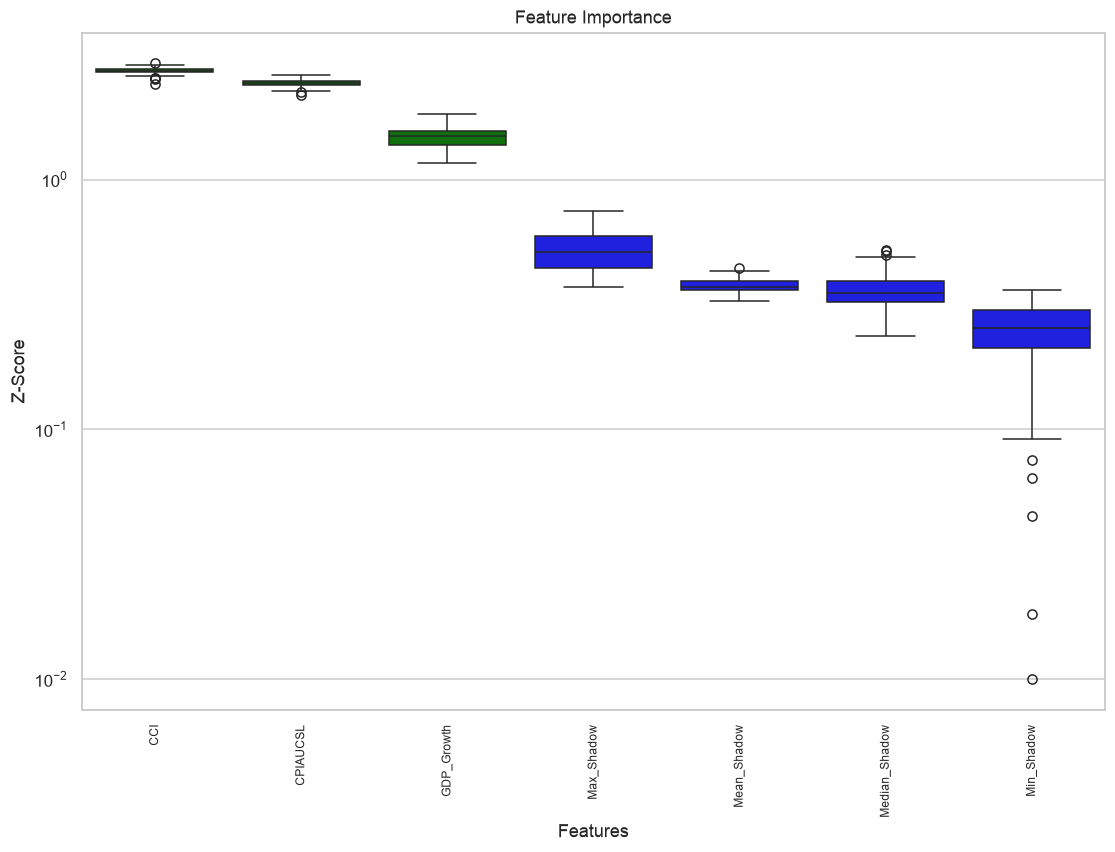

Feature: CPIAUCSL             Rank: 3 (0.152),  Keep: Confirmed
Feature: GDP_Growth           Rank: 2 (0.093),  Keep: Confirmed
Feature: CCI                  Rank: 1 (0.177),  Keep: Confirmed


In [79]:
### Boruta using `BorutaShap`
## Note: n_trials=100 takes several minutes; lower it while you are experimenting.
## Requires `shap` (pip install shap) and boruta_shap.py next to this notebook.

cps_Y = full_df['volatility']
cps_X2 = full_df.drop(['volatility', 'DATE', 'UNRATE_Change', 'FedFunds_Change'], axis=1).select_dtypes(include='number')

# Run Boruta algorithm
Feature_Selector = BorutaShap(importance_measure='shap', classification=False)
Feature_Selector.fit(X=cps_X2, y=cps_Y, n_trials=100, random_state=90095)

# Plot results
Feature_Selector.plot(which_features='all')
plt.show()

# Print results
boruta_keep2 = ['Confirmed' if p in Feature_Selector.accepted else
                'Tentative' if p in Feature_Selector.tentative else
                'Reject' for p in Feature_Selector.all_columns]

boruta_features2 = zip(Feature_Selector.all_columns,
                        len(Feature_Selector.shap_values) - np.argsort(Feature_Selector.shap_values),
                        Feature_Selector.shap_values,
                        boruta_keep2)
for feat in boruta_features2:
    print('Feature: {:<20} Rank: {} ({:.3f}),  Keep: {}'.format(feat[0], feat[1], feat[2], feat[3]))

In [80]:
#Apply Mallows Cp criterion for variable selection

!pip install RegscorePy

In [81]:
%pip install mlxtend

Note: you may need to restart the kernel to use updated packages.


Features: 31/31

Best subset: ['CPIAUCSL', 'GDP_Growth', 'CCI', 'FedFunds_Change']


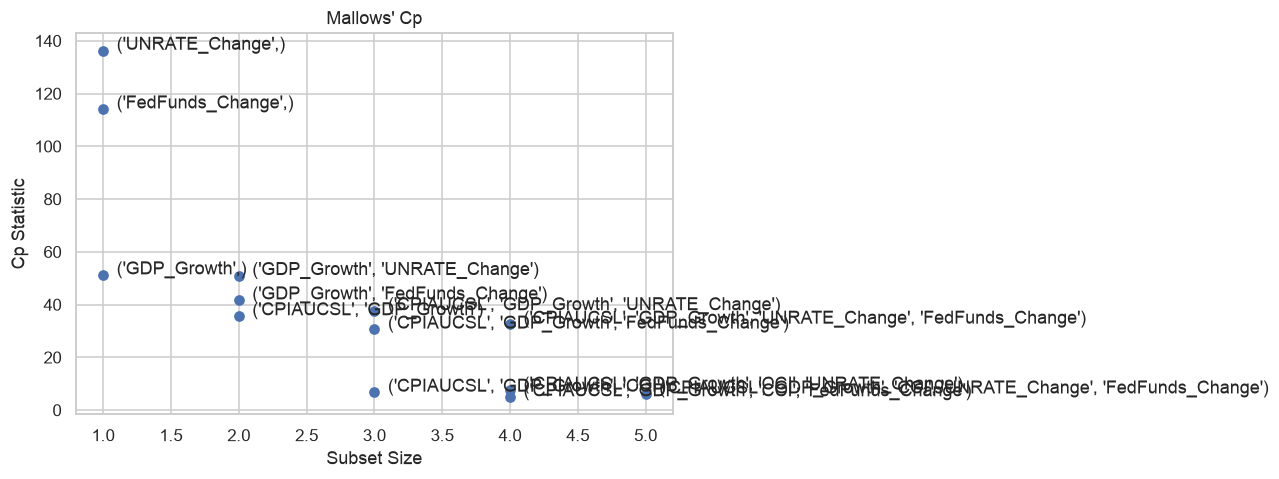

,,subsets,Cp
subsets,,,
4,"(CPIAUCSL, GDP_Growth, CCI, FedFunds_Change)",4,4.935184
5,"(CPIAUCSL, GDP_Growth, CCI, UNRATE_Change, FedFunds_Change)",5,6.000000
3,"(CPIAUCSL, GDP_Growth, CCI)",3,6.683147
4,"(CPIAUCSL, GDP_Growth, CCI, UNRATE_Change)",4,7.477684
3,"(CPIAUCSL, GDP_Growth, FedFunds_Change)",3,30.600666
4,"(CPIAUCSL, GDP_Growth, UNRATE_Change, FedFunds_Change)",4,32.458659
2,"(CPIAUCSL, GDP_Growth)",2,35.648047
3,"(CPIAUCSL, GDP_Growth, UNRATE_Change)",3,37.566104
2,"(GDP_Growth, FedFunds_Change)",2,41.659272


In [82]:
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression
from mlxtend.feature_selection import ExhaustiveFeatureSelector as EFS
from mlxtend.feature_selection import SequentialFeatureSelector as SFS



# First get some estimates from the full regression

volatility_full = smf.ols('volatility ~ FedFunds_Change + GDP_Growth + CCI + CPIAUCSL + UNRATE_Change', data=full_df).fit()
volatility_full_sig2 = volatility_full.mse_resid # residual MSE = sigma^2 hat
volatility_n, _ = full_df.shape

# Negative Mallows' cp, so we want largest

def negative_mallows(estimator, X, y):
    y_pred = estimator.predict(X)
    sse = np.sum((y - y_pred) ** 2)
    p = estimator.n_features_in_ + 1 # number features doesn't include bias term
    cp = sse / volatility_full_sig2 + 2*p - volatility_n    
    return -cp

# Set up regression

vol_Y = full_df['volatility'].values
vol_X = full_df.drop(['volatility', 'DATE'], axis=1).select_dtypes(include='number')
lr = LinearRegression(fit_intercept=True)

# Using `ExhaustiveFeatureSelector` from `mlxtend`

vol_efs = EFS(lr,
              min_features=1,
              max_features=5,
              scoring=negative_mallows,
              cv=None)

# Run regressions

vol_efs.fit(vol_X, vol_Y)
print('Best subset:', [vol_efs.feature_names[i] for i in vol_efs.best_idx_])

# Extract Mallows' Cp data

vol_efs_features = [vol_efs.subsets_[p]['feature_names'] for p in vol_efs.subsets_]
vol_efs_subset = [len(vol_efs.subsets_[p]['feature_idx']) for p in vol_efs.subsets_]
vol_efs_cp = [ -vol_efs.subsets_[p]['avg_score'] for p in vol_efs.subsets_]
vol_mallows = pd.DataFrame({'subsets':vol_efs_subset, 'Cp':vol_efs_cp}, index=vol_efs_features)

# Top 3 best, by subset

vol_mallows_best = vol_mallows.groupby('subsets')[['subsets','Cp']].apply(lambda x: x.nsmallest(3, 'Cp'))
vol_mallows_best

# Plotting best subsets

plt.scatter(vol_mallows_best['subsets'], vol_mallows_best['Cp'])
plt.title("Mallows' Cp")
plt.xlabel('Subset Size')
plt.ylabel('Cp Statistic')
for i,sub in enumerate(vol_mallows_best['subsets']):
    subset = vol_mallows_best.index[i][1]
    plt.annotate(subset, (sub + 0.1, vol_mallows_best.iloc[i]['Cp'] + 0.3)) # to plot labels
plt.show()

# And the associated sorted data frame

vol_mallows_best.sort_values('Cp')

In [83]:
#the smaller the CP values the better

In [84]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
# VIF computation setup
vol_exog = full_df.drop(['volatility', 'DATE', 'UNRATE_Change', 'FedFunds_Change'], axis=1).select_dtypes(include='number') # exogenous variables only
vol_exog_vars = vol_exog.columns
vol_exog = sm.add_constant(vol_exog)

# Compute VIF

vol_VIF = []
for i,v in enumerate(vol_exog_vars):
    vol_VIF.append(variance_inflation_factor(exog=vol_exog, exog_idx=i+1)) # `exog_idx` is col index of predictor
# Print
pd.DataFrame({
    'Variable':vol_exog_vars,
    'VIF':vol_VIF
}).sort_values(by='VIF')

,Variable,VIF
1,GDP_Growth,1.442424
0,CPIAUCSL,1.896018
2,CCI,2.483953


In [85]:
#Running our best predictor

fit_1 = smf.ols('volatility ~ GDP_Growth', data=full_df).fit()
print(fit_1.summary())

                            OLS Regression Results                            
Dep. Variable:             volatility   R-squared:                       0.382
Model:                            OLS   Adj. R-squared:                  0.379
Method:                 Least Squares   F-statistic:                     108.3
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           4.75e-20
Time:                        17:06:19   Log-Likelihood:                -142.10
No. Observations:                 177   AIC:                             288.2
Df Residuals:                     175   BIC:                             294.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.6598      0.068     24.362      0.0

In [86]:
#Running our second best model

fit_2 = smf.ols('volatility ~ GDP_Growth + CPIAUCSL + CCI', data=full_df).fit()
print(fit_2.summary())

                            OLS Regression Results                            
Dep. Variable:             volatility   R-squared:                       0.516
Model:                            OLS   Adj. R-squared:                  0.507
Method:                 Least Squares   F-statistic:                     61.45
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           4.26e-27
Time:                        17:06:19   Log-Likelihood:                -120.53
No. Observations:                 177   AIC:                             249.1
Df Residuals:                     173   BIC:                             261.8
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     25.8410      4.112      6.285      0.0

In [87]:
#Running our third best model

fit_3 = smf.ols('volatility ~ GDP_Growth + CPIAUCSL + CCI + FedFunds_Change', data=full_df).fit()
print(fit_3.summary())

                            OLS Regression Results                            
Dep. Variable:             volatility   R-squared:                       0.526
Model:                            OLS   Adj. R-squared:                  0.515
Method:                 Least Squares   F-statistic:                     47.76
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           5.82e-27
Time:                        17:06:19   Log-Likelihood:                -118.63
No. Observations:                 177   AIC:                             247.3
Df Residuals:                     172   BIC:                             263.1
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          24.5837      4.131     

## Final Model and Diagnositcs and Robustness

In [88]:
#Inital OLS model and Diagnostic Plots based on final Model 2

volatility_mod = smf.ols('volatility ~ GDP_Growth + CPIAUCSL + CCI',data=full_df).fit()

                            OLS Regression Results                            
Dep. Variable:             volatility   R-squared:                       0.516
Model:                            OLS   Adj. R-squared:                  0.507
Method:                 Least Squares   F-statistic:                     61.45
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           4.26e-27
Time:                        17:06:19   Log-Likelihood:                -120.53
No. Observations:                 177   AIC:                             249.1
Df Residuals:                     173   BIC:                             261.8
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     25.8410      4.112      6.285      0.0

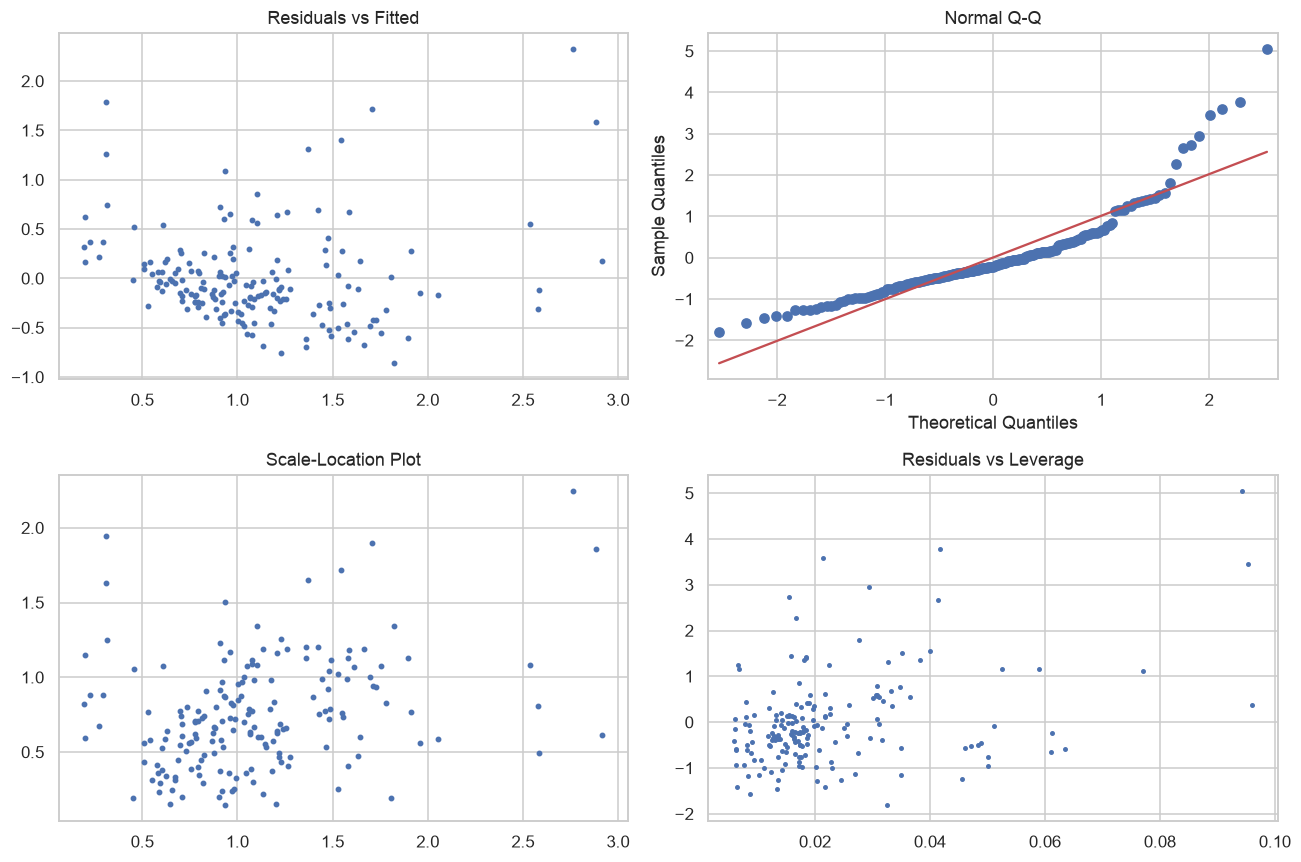

In [89]:
# Some calculations on residuals

vol_mod_std_resid = volatility_mod.get_influence().resid_studentized_internal
vol_mod_lev = volatility_mod.get_influence().hat_matrix_diag

# Summary

print(volatility_mod.summary())

# Diagnostic plots

fig2, ax2 = plt.subplots(2, 2, figsize=(12, 8))

ax2[0,0].scatter(x=volatility_mod.fittedvalues, y=volatility_mod.resid, s=8)
ax2[0,0].set_title('Residuals vs Fitted')

sm.qqplot(vol_mod_std_resid, line='s', ax=ax2[0,1])
ax2[0,1].set_title('Normal Q-Q')

ax2[1,0].scatter(
    x=volatility_mod.fittedvalues,
    y=np.sqrt(np.abs(vol_mod_std_resid)),
    s=8
)
ax2[1,0].set_title('Scale-Location Plot')

ax2[1,1].scatter(x=vol_mod_lev, y=vol_mod_std_resid, s=5)
ax2[1,1].set_title('Residuals vs Leverage')

plt.tight_layout()
plt.show()

Inital model estimates the relationship between S&P 500 Volatility and three macroeconomic indicators (GDP Growth, CPI, and CCI). The regression produced an Adj R^2 of 0.507, indicating that approximately 50.7% of the variation in monthly stock volatility was explained by our x variables. The overall model is also statistically significant

In [90]:
#RETEST

import statsmodels.stats.outliers_influence as oi

test = oi.reset_ramsey(volatility_mod, degree=2)

print("Ramsey-RESET:")
print(test)

Ramsey-RESET:
<F test: F=42.420688953031785, p=7.803786486715058e-10, df_denom=172, df_num=1>


Ho: Additional nonlinear terms are not needed

Ha: They are needed

Since the p value is < 0.05, we reject the null, suggesting that the linear model will have misspecification

In [91]:
#Quadratic Model

print("Quadratic Model")

smf.ols(formula='volatility ~ GDP_Growth + CPIAUCSL + CCI + I(GDP_Growth**2)',data=full_df).fit().summary()

Quadratic Model


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             volatility   R-squared:                       0.617
Model:                            OLS   Adj. R-squared:                  0.608
Method:                 Least Squares   F-statistic:                     69.24
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           7.90e-35
Time:                        17:06:19   Log-Likelihood:                -99.824
No. Observations:                 177   AIC:                             209.6
Df Residuals:                     172   BIC:                             225.5
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             23.6216      3.683      6.414      0.000      16.352      30.891
GDP_Growth            -0.6457      0.061    -10.581      0.000      -0.766      -0.525
CPIAUCSL              -0.0147      0.002     -6.692      0.000      -0.019      -0.010
CCI                   -0.1929      0.034     -5.664      0.000      -0.260      -0.126
I(GDP_Growth ** 2)     0.2080      0.031      6.734      0.000       0.147       0.269
==============================================================================
Omnibus:                       60.645   Durbin-Watson:                   1.124
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              144.995
Skew:                           1.506   Prob(JB):                     3.27e-32
Kurtosis:                       6.253   Cond. No.                     2.60e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.6e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Strong evidence of nonlinear relationship between GDP growth and stock market volatility. 

Adj R^2: 0.617: Explains approximately 61/7% of the variation in monthly volatility

F stat: 69.24. Model is stat. significant

AIC: 209.6 which is < 249.1 (model 2)

BIC: 225.5 which is < 261.8 (model 2)

The relationship between GDP growth and volatility is negative but magnitude is dependent on level of growth because this model includes a squared term - this negative association will essentially decrease as GDP growth increases

Holding all else constant, a one unit increase in CPI is associated with a 0.0147 point decrease in volatility

Holding all else constant, a one unit increase in cci is associated with a 0.1929 point decrease in volatility


Jarque Bera = 144.995. p value < 0.01. Rejects residual normality, so estimations need to be interpreted with a grain of salt

In [92]:
#Interaction Model

print("Interaction Model")

smf.ols(formula='volatility ~ GDP_Growth + CPIAUCSL + CCI + GDP_Growth*CCI',data=full_df).fit().summary()

Interaction Model


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             volatility   R-squared:                       0.608
Model:                            OLS   Adj. R-squared:                  0.599
Method:                 Least Squares   F-statistic:                     66.59
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           6.07e-34
Time:                        17:06:19   Log-Likelihood:                -101.94
No. Observations:                 177   AIC:                             213.9
Df Residuals:                     172   BIC:                             229.8
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         37.0422      4.111      9.011      0.000      28.928      45.157
GDP_Growth       -14.9575      2.291     -6.530      0.000     -19.479     -10.436
CPIAUCSL          -0.0139      0.002     -6.184      0.000      -0.018      -0.009
CCI               -0.3306      0.039     -8.420      0.000      -0.408      -0.253
GDP_Growth:CCI     0.1474      0.023      6.342      0.000       0.102       0.193
==============================================================================
Omnibus:                       53.183   Durbin-Watson:                   1.122
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              107.797
Skew:                           1.402   Prob(JB):                     3.91e-24
Kurtosis:                       5.598   Cond. No.                     3.26e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.26e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Using the same economic predictors as Model 2, with the additional interaction between GDP growth and cci. 

Adj R^2: 0.599. The interaction coefficient is positive between GDP growth and CCI (0.1474). This interaction improved the over model fit, the quadratic model still performed better according to the Adj R^2, AIC and BIC. 

In [93]:
#Saving quad, interaction and final model
volatility_interaction = smf.ols('volatility ~ GDP_Growth + CPIAUCSL + CCI + GDP_Growth*CCI',data=full_df).fit() #Interaction
volatility_mod = smf.ols('volatility ~ GDP_Growth + CPIAUCSL + CCI',data=full_df).fit() #Linear
volatility_quad = smf.ols('volatility ~ GDP_Growth + CPIAUCSL + CCI + I(GDP_Growth**2)',data=full_df).fit() #Quad 

In [94]:
#Based on AIC, BIC and Adj R^2, Quad model is better

#### Breusch-Pagan Test

In [95]:
#Breusch-Pagan Test using `statsmodels.stats.diagnostic`

from statsmodels.stats.diagnostic import het_breuschpagan


In [96]:

vol_bp = het_breuschpagan(resid=volatility_quad.resid, exog_het=volatility_quad.model.exog)

print(f'Test statistic: \t{vol_bp[0]:.5f}\np-value: \t\t{vol_bp[1]:.5f}')

#Result: Since p value < 0.05, reject the null, and there is heteroskedasticty present

Test statistic: 	13.91856
p-value: 		0.00756


0.00756 < 0.05, we reject the null and can infer that there is statistically significant evidence of heteroskedasticity. Variance of errors is not constant

#### White Test

In [97]:
from statsmodels.stats.diagnostic import het_white

In [98]:
# White Test using statsmodels.stats.diagnostic

vol_white = het_white(resid=volatility_quad.resid, exog=volatility_quad.model.exog)
print(f'Test statistic: \t{vol_white[0]:.5f}\np-value: \t\t{vol_white[1]:.5f}')

#results: also reject the null since p value is < 0.05

Test statistic: 	30.16518
p-value: 		0.00446


The quadratic model is still the best fit given the Adj R^2, AIC and BIC, but both tests confirm constant error variance assumption is violated

#### Scale-Location Plots

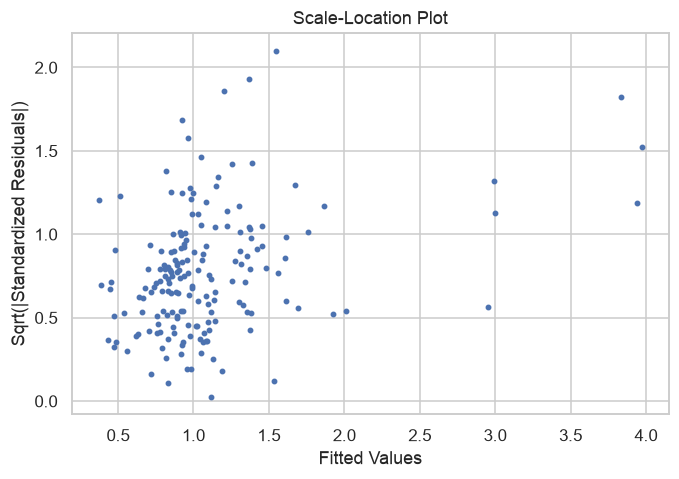

In [99]:
# Scale-Location Plot

vol_quad_std_resid = volatility_quad.get_influence().resid_studentized_internal

plt.scatter(
    x=volatility_quad.fittedvalues,
    y=np.sqrt(np.abs(vol_quad_std_resid)),
    s=8
)

plt.xlabel('Fitted Values')
plt.ylabel('Sqrt(|Standardized Residuals|)')
plt.title('Scale-Location Plot')
plt.show()

Most observations are clustered around 0.5-1.5. Consistent with BP and White test

### Normality of Residuals & Histogram of Residuals

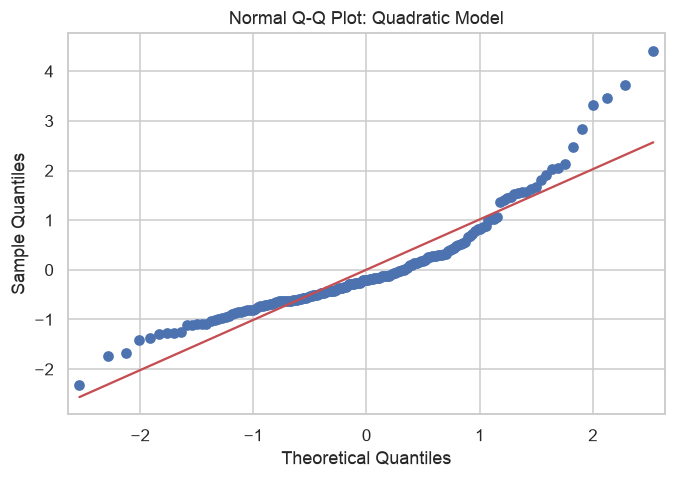

In [100]:
#QQ Plot: Quadratic Model - gave the best results via aic and bic 

vol_quad_std_resid = volatility_quad.get_influence().resid_studentized_internal

sm.qqplot(vol_quad_std_resid, line='s')
plt.title('Normal Q-Q Plot: Quadratic Model')
plt.show()

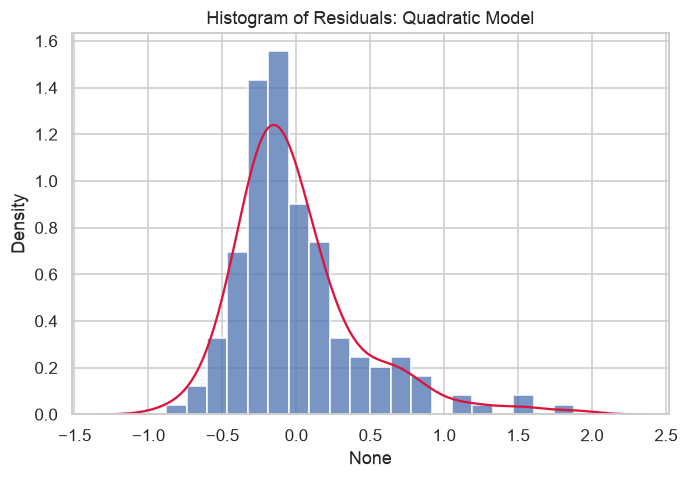

JB:	 145.0
p-val:	 3.272e-32
skew:	 1.506
kurt:	 6.253


In [101]:
#Jarque Bera test
# A plot of the estimate of the errors, i.e., the residuals, shows that they are heteroskedastic.

sns.histplot(x=volatility_quad.resid, stat='density')
sns.kdeplot(x=volatility_quad.resid, color='crimson')
plt.title('Histogram of Residuals: Quadratic Model')
plt.show()

# Performing Jarque-Bera test
# H0: Residuals are normally distributed
# HA: Residuals are not normally distributed

vol_jb_test = sms.stattools.jarque_bera(volatility_quad.resid)
for p,q in zip(['JB', 'p-val', 'skew', 'kurt'], vol_jb_test): print(f'{p}:\t {q:.4}')

##### JB shows extreme abnormality but atleast it is statistically significant but at what cost

Residuals are concentrated around 0, right skewed

### Outliers and Influence

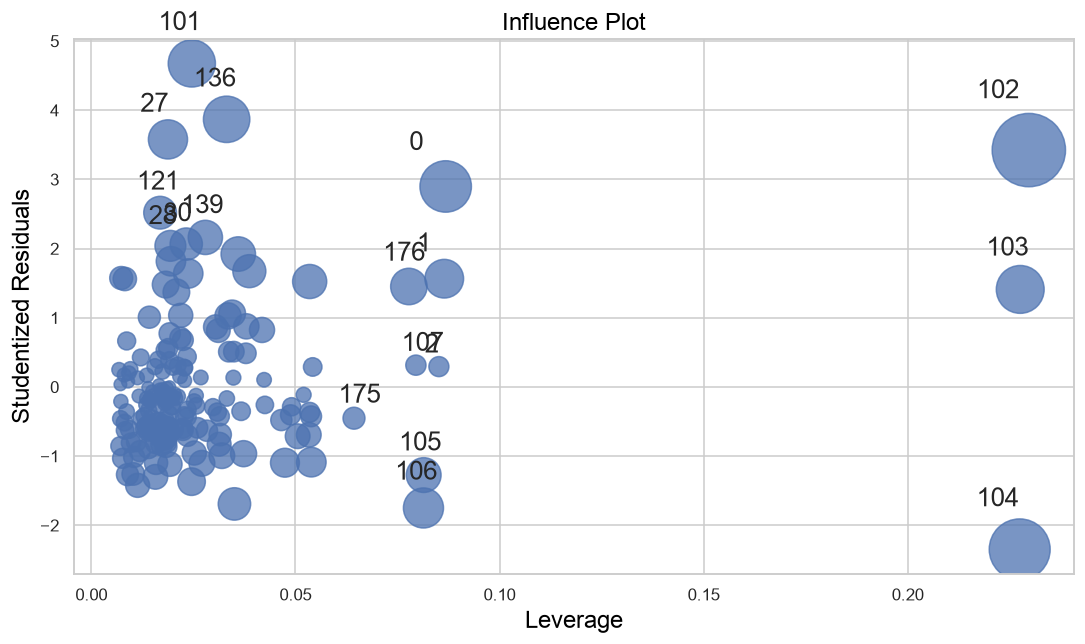

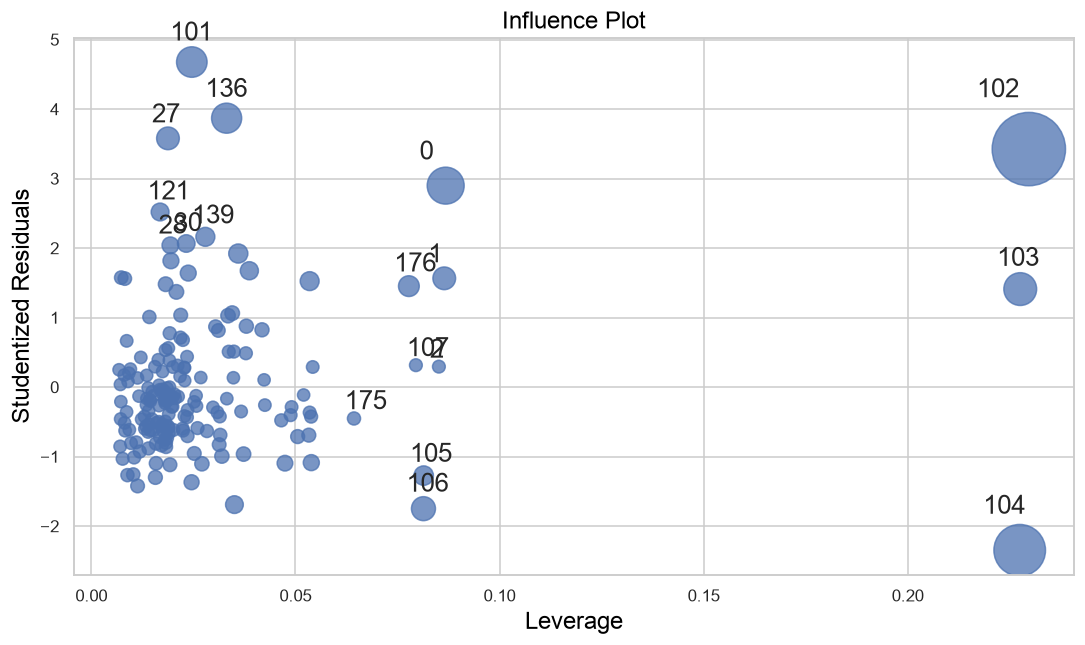

In [102]:
#Cooks Distance Plot

figd, ax = plt.subplots(figsize=(10,6))
figd = sm.graphics.influence_plot(volatility_quad, ax = ax, criterion="DFFITS")
figd.tight_layout(pad=1.0)

fige, ax = plt.subplots(figsize=(10,6))
fige = sm.graphics.influence_plot(volatility_quad, ax = ax, criterion="cooks")
fige.tight_layout(pad=1.0)

In [103]:
volatility_quad_influence = volatility_quad.get_influence().summary_frame()
volatility_quad_influence.sort_values('cooks_d', ascending = False).head()

,dfb_Intercept,dfb_GDP_Growth,dfb_CPIAUCSL,dfb_CCI,dfb_I(GDP_Growth ** 2),cooks_d,standard_resid,hat_diag,dffits_internal,student_resid,dffits
102,-0.153707,-1.594179,0.181366,0.154107,1.434972,0.658003,3.321982,0.229660,1.813839,3.423974,1.869528
104,-0.011773,1.040404,-0.006885,0.006787,-0.968378,0.316309,-2.317916,0.227421,-1.257596,-2.348133,-1.273990
0,-0.211652,-0.136255,-0.027155,0.229360,0.643871,0.153066,2.837609,0.086798,0.874831,2.897995,0.893447
103,-0.004610,-0.629141,0.019174,0.006670,0.583294,0.116405,1.405611,0.227552,0.762905,1.409639,0.765091
101,0.449165,0.095417,-0.205701,-0.455538,-0.267112,0.098398,4.416062,0.024607,0.701420,4.676281,0.742751


In [104]:
full_df.loc[104]

DATE               2008-12-01 00:00:00
CPIAUCSL                       211.398
GDP_Growth                   -1.951742
CCI                           96.38508
volatility                    3.091874
UNRATE_Change                      0.5
FedFunds_Change                  -0.23
Period                 Great Recession
Name: 104, dtype: object

In [105]:
full_df.loc[0]

DATE               2000-04-01 00:00:00
CPIAUCSL                         170.9
GDP_Growth                    2.454875
CCI                           102.9009
volatility                    2.095314
UNRATE_Change                     -0.2
FedFunds_Change                   0.17
Period                   Pre-Recession
Name: 0, dtype: object

In [106]:
full_df.loc[103]

DATE               2008-11-01 00:00:00
CPIAUCSL                       213.153
GDP_Growth                   -1.951742
CCI                           96.39321
volatility                    4.476468
UNRATE_Change                      0.3
FedFunds_Change                  -0.58
Period                 Great Recession
Name: 103, dtype: object

In [107]:
full_df.loc[101]

DATE               2008-09-01 00:00:00
CPIAUCSL                       218.877
GDP_Growth                    0.223992
CCI                           97.05766
volatility                    3.426061
UNRATE_Change                      0.0
FedFunds_Change                  -0.19
Period                 Great Recession
Name: 101, dtype: object

In [108]:
full_df.loc[102]

DATE               2008-10-01 00:00:00
CPIAUCSL                       216.995
GDP_Growth                   -1.951742
CCI                           96.67294
volatility                    5.090923
UNRATE_Change                      0.4
FedFunds_Change                  -0.84
Period                 Great Recession
Name: 102, dtype: object

Most observations have relatively low leverage, but there are a few observations that may be influential (104, 103, 102, 101, etc). These observations may disproportionately affect the estimated reg coefficients. Before removing these observation, we need to examine the cook's distance and DFBETAS estimate to determine how strongly they are affecting our estimate.

We will not be dropping these outliers as 4 out of 5 of them are during the Great Recession period. In addition, if there are a lot of outliers, chances are they represent extreme volatility reactions. 

### DFBETAS

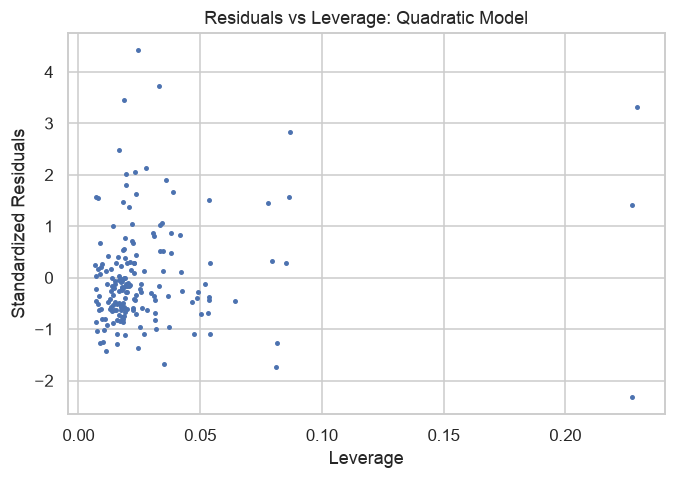

In [109]:
# Some calculations on residuals

vol_quad_std_resid = volatility_quad.get_influence().resid_studentized_internal # standardized residuals
vol_quad_lev = volatility_quad.get_influence().hat_matrix_diag # leverage values

#Residuals vs Leverage

plt.scatter(x=vol_quad_lev, y=vol_quad_std_resid, s=5)
plt.title('Residuals vs Leverage: Quadratic Model')
plt.xlabel('Leverage')
plt.ylabel('Standardized Residuals')
plt.show()

Most observations have a low leverage as they are mostly clustered around 0.01 5o 0.05. 

Some predictors do have unusually large residuals as they exceed 4 or 4. This indicates that stock market volatility could be considered higher then the model predicted. 

There are a few observation on the right near 0.20, which could indicate unsual combinations of macroeconomic predictor values

Potentially influential observations are present. This could effect the estimated coefficients, which is consistent with the cook's distance results. 

In [110]:
#DFBETAS

vol_quad_dfbetas = volatility_quad.get_influence().dfbetas

dfbetas_df = pd.DataFrame(vol_quad_dfbetas,columns=volatility_quad.params.index)

dfbetas_df.head()

,Intercept,GDP_Growth,CPIAUCSL,CCI,I(GDP_Growth ** 2)
0,-0.211652,-0.136255,-0.027155,0.229360,0.643871
1,-0.112577,-0.072492,-0.014553,0.121955,0.347593
2,-0.019694,-0.012749,-0.002924,0.021339,0.065201
3,-0.043791,-0.025492,0.003016,0.048127,-0.016679
4,0.102766,0.060003,-0.005786,-0.113141,0.040106


In [111]:
dfbetas_df.abs().max().sort_values(ascending=False)

GDP_Growth            1.594179
I(GDP_Growth ** 2)    1.434972
CCI                   0.535871
Intercept             0.516201
CPIAUCSL              0.357364
dtype: float64

Trying to measure how much each regression coeff changes when an observation is removed. Observation 0 stands out the most as it is the highest. The value +0.6439 indicates that choosing to exlude observation 0 would decrease the estimated coefficient on gdp growth^2. The estimated nonlinear relationship may be sensitive to specific obs. 

GDP growth has an observation (atleast 1) that substantially impacts the GDP growth coefficient. 

GDP growth^2 has an observation (atleast 1) that also substantially impacts the estimated relationship (nonlinear) between GDP and volatility

### Robustness Analysis

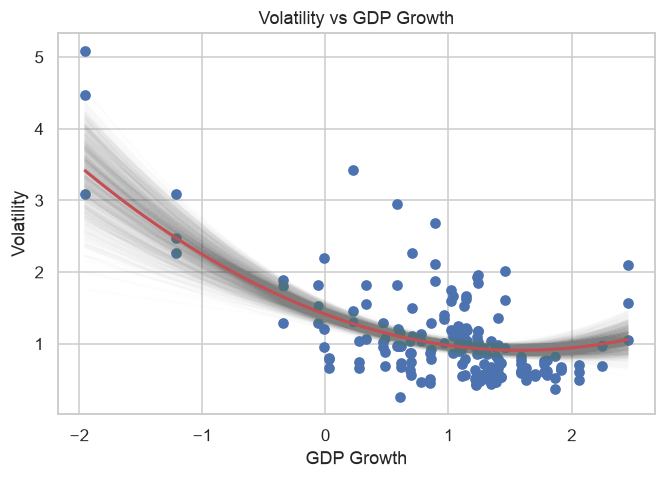

In [112]:
#Bootstrapping 

n_boot = 1000

boot_rmse = []
boot_b1 = []
boot_b2 = []
boot_b3 = []
boot_b4 = []
boot_b5 = []
boot_sig2hat = []
boot_r2 = []

vol_span_x = pd.DataFrame({
    'GDP_Growth': np.linspace(full_df['GDP_Growth'].min(),
                              full_df['GDP_Growth'].max(), 200),
    'CPIAUCSL': full_df['CPIAUCSL'].mean(),
    'CCI': full_df['CCI'].mean()
})

plt.figure()

for _ in range(n_boot):
    # Sampling with replacement
    vol_sample = full_df.sample(n=full_df.shape[0], replace=True)
    vol_sample_ols = smf.ols(
        'volatility ~ GDP_Growth + CPIAUCSL + CCI + I(GDP_Growth**2)',
        data=vol_sample
    ).fit()

    # Append coefficients
    boot_b1.append(vol_sample_ols.params.iloc[0])  # intercept
    boot_b2.append(vol_sample_ols.params.iloc[1])  # GDP Growth
    boot_b3.append(vol_sample_ols.params.iloc[2])  # CPI
    boot_b4.append(vol_sample_ols.params.iloc[3])  # CCI
    boot_b5.append(vol_sample_ols.params.iloc[4])  # GDP Growth squared
    # Performance measures
    boot_sig2hat.append(vol_sample_ols.scale)
    boot_rmse.append(np.sqrt(np.mean(vol_sample_ols.resid ** 2)))
    boot_r2.append(vol_sample_ols.rsquared)

    # Plot a greyed out curve for this iteration
    vol_sample_yhat = vol_sample_ols.predict(vol_span_x)
    plt.plot(vol_span_x['GDP_Growth'], vol_sample_yhat,
             color='grey', alpha=0.01)

# Fit averaged model
vol_ols_span_y = (
    np.mean(boot_b1)
    + vol_span_x['GDP_Growth'] * np.mean(boot_b2)
    + vol_span_x['CPIAUCSL'] * np.mean(boot_b3)
    + vol_span_x['CCI'] * np.mean(boot_b4)
    + vol_span_x['GDP_Growth']**2 * np.mean(boot_b5)
)

# Plotting the fitted curves
plt.scatter(full_df['GDP_Growth'], full_df['volatility'])
plt.plot(vol_span_x['GDP_Growth'], vol_ols_span_y,
         color='r', linewidth=2)
plt.xlabel('GDP Growth')
plt.ylabel('Volatility')
plt.title('Volatility vs GDP Growth')
plt.show()

Nonlinear, ushaped distrubution and relationship between GDP and Volatility. Blue points are the observed volatility units, gray curves are our 1000 bootstrap sampled. The red line represents the relationship between avg bootstrap coefficient. 

Volatility is decreasing as GDp growth increases, before the estimated curve turns slightly upward as GDP rate continues to grow. 

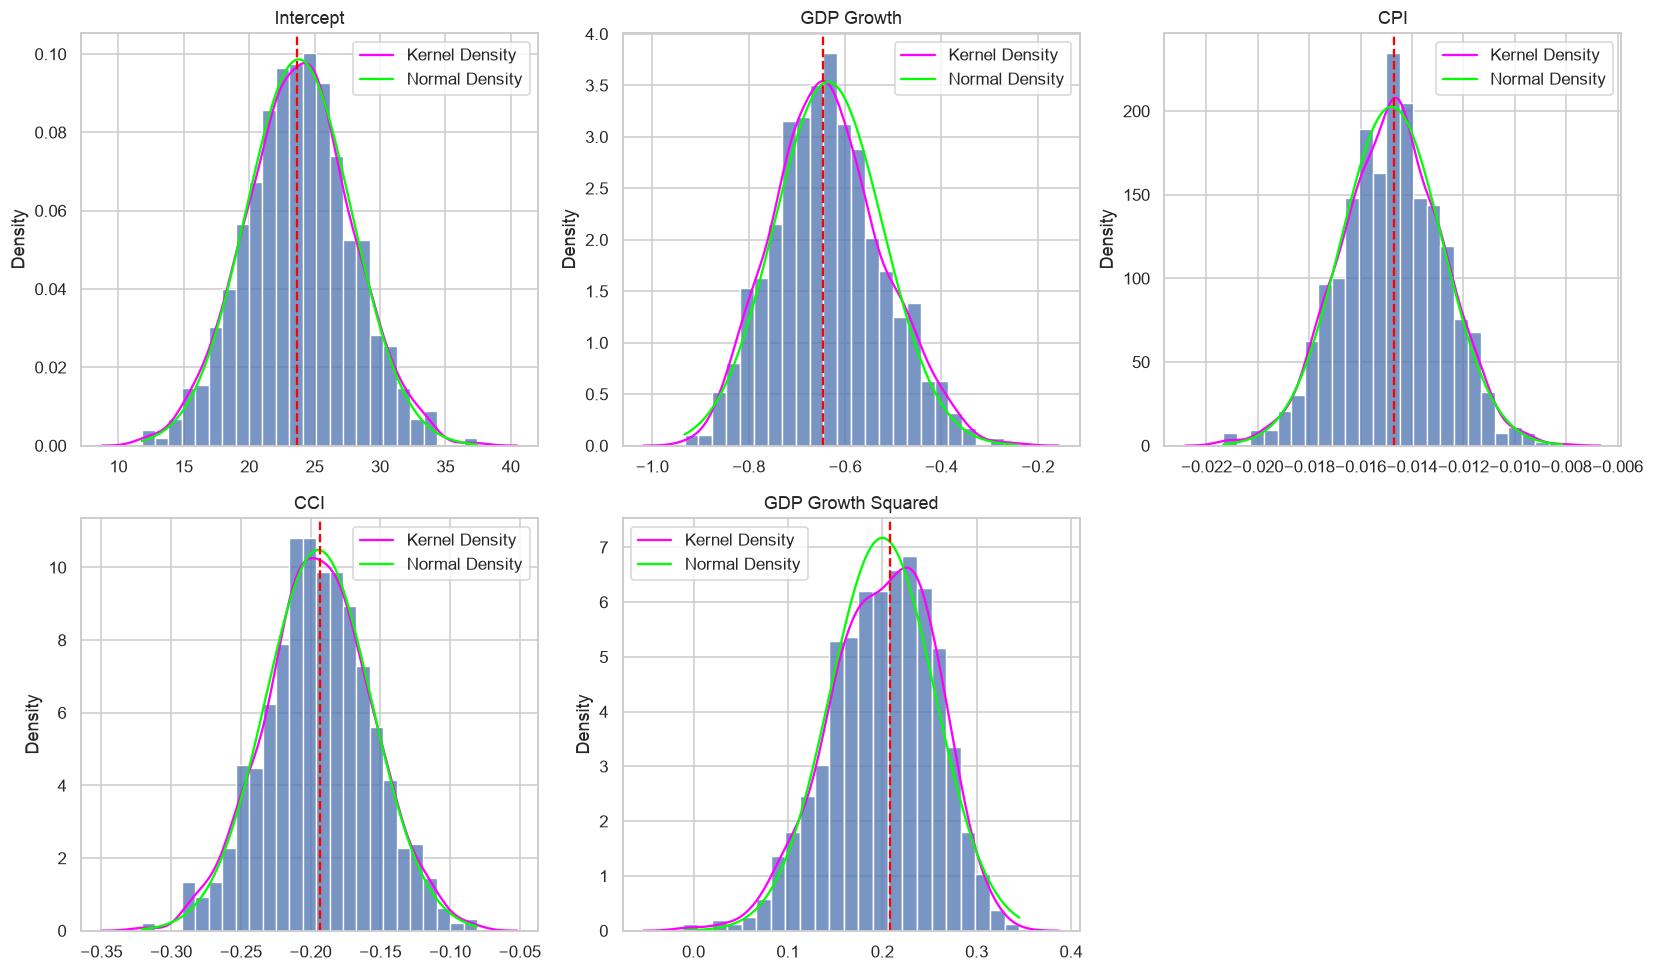

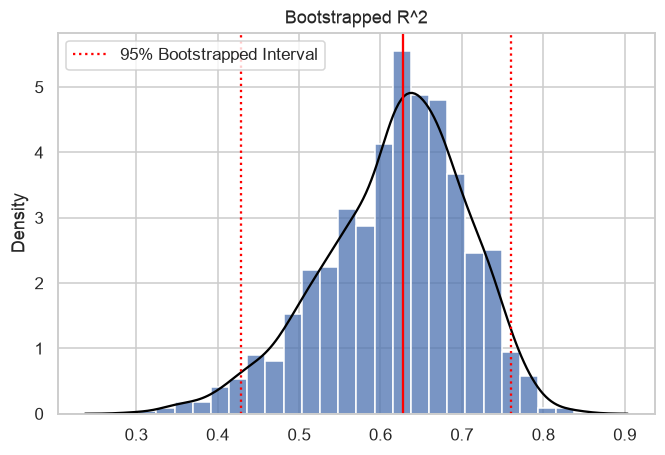

--- sigma hat ---
estimate:		0.42019
std error:		0.036971
median:			0.41865
2.5 percentile:		0.34911
97.5 percentile:	0.49469


In [113]:
#Distributions of the estimates


# For plotting normal PDFs
boot_b = [boot_b1, boot_b2, boot_b3, boot_b4, boot_b5]
coefficient_names = ['Intercept', 'GDP Growth', 'CPI', 'CCI', 'GDP Growth Squared']

# Plotting beta estimates
fig6, ax6 = plt.subplots(2, 3, figsize=(15, 9))
for i in range(5):
    b_range = np.linspace(np.min(boot_b[i]), np.max(boot_b[i]), 200)

    sns.histplot(boot_b[i], stat='density', kde=False, ax=ax6.flat[i])
    sns.kdeplot(boot_b[i], color='fuchsia', ax=ax6.flat[i], label='Kernel Density')
    sns.lineplot(x=b_range, y=norm.pdf(b_range, np.mean(boot_b[i]), np.std(boot_b[i])),
                 color='lime', ax=ax6.flat[i], label='Normal Density')
    ax6.flat[i].axvline(x=volatility_quad.params.iloc[i], color='red',
                        linestyle='--', label='OLS Estimate')
    ax6.flat[i].set_title(coefficient_names[i])

ax6.flat[5].axis('off')
plt.tight_layout()
plt.show()

# Bootstrap for distribution of R^2 (coefficient of determination)
sns.histplot(boot_r2, stat='density', kde=False)
sns.kdeplot(boot_r2, color='black')
plt.axvline(x=np.quantile(boot_r2, q=0.025), color='red', linestyle=':', label='95% Bootstrapped Interval')
plt.axvline(x=np.quantile(boot_r2, q=0.5), color='red')
plt.axvline(x=np.quantile(boot_r2, q=0.975), color='red', linestyle=':')
plt.title('Bootstrapped R^2')
plt.legend()
plt.show()

# Bootstrap for estimated residual standard deviation
boot_stdhat = np.sqrt(boot_sig2hat)
print('--- sigma hat ---\n' +
      f'estimate:\t\t{boot_stdhat.mean():.5}\n' +
      f'std error:\t\t{boot_stdhat.std():.5}\n' +
      f'median:\t\t\t{np.quantile(boot_stdhat, q=0.5):.5}\n' +
      f'2.5 percentile:\t\t{np.quantile(boot_stdhat, q=0.025):.5}\n' +
      f'97.5 percentile:\t{np.quantile(boot_stdhat, q=0.975):.5}'
      )

Bell shaped curves, and GDP growth seems to exhbit some symmetry. The bootstrap means are close with the OLS estimates. GDP growth^2 remains positive as well. 

In [114]:
# Compare bootstrap estimates with OLS estimates

boot_b = [boot_b1, boot_b2, boot_b3, boot_b4, boot_b5]

bootstrap_comparison = pd.DataFrame({
    'OLS Estimate': volatility_quad.params.values,
    'Bootstrap Mean': [np.mean(b) for b in boot_b],
    'Bootstrap Std Error': [np.std(b, ddof=1) for b in boot_b],
    '2.5 Percentile': [np.quantile(b, 0.025) for b in boot_b],
    '97.5 Percentile': [np.quantile(b, 0.975) for b in boot_b]
}, index=volatility_quad.params.index)

print(bootstrap_comparison.round(4))

                    OLS Estimate  Bootstrap Mean  Bootstrap Std Error  2.5 Percentile  97.5 Percentile
Intercept                23.6216         23.7898               4.0457         15.7867          31.8590
GDP_Growth               -0.6457         -0.6348               0.1130         -0.8350          -0.4034
CPIAUCSL                 -0.0147         -0.0148               0.0020         -0.0187          -0.0110
CCI                      -0.1929         -0.1944               0.0381         -0.2710          -0.1193
I(GDP_Growth ** 2)        0.2080          0.2002               0.0556          0.0867           0.2983


The bootstrap coefficients distributions were generally centered around the original OLS estimates, suggesting tha the estimated relationships remained stable through resampling. The bootsrap average for GDP growth was -0.6348 whereas the OLS had an estimate of -0.6457. The mean for GDP growth ^2 was 0.2025 and the ols estimate was 0.2080. 

Overall, the bootstrap results suggest that the quadratic model's coeeficient are stable under the resampling. 

### Model Validation

In [115]:
#5-fold validation and out of sample prediction accuracy

x = full_df[['GDP_Growth', 'CPIAUCSL', 'CCI']].copy()
x['GDP_Growth_Squared'] = full_df['GDP_Growth']**2
y = full_df['volatility']

scores = cross_val_score(LinearRegression(), x, y, cv=5, scoring='neg_root_mean_squared_error')
print('5-Fold CV RMSE Scores:', np.abs(scores))
print('Mean CV RMSE:', np.abs(scores).mean())

5-Fold CV RMSE Scores: [0.72145302 0.50538716 0.5541769  0.51117747 0.34171825]
Mean CV RMSE: 0.5267825602828486


We did a 5fold cross validation test using the volatility quadratic model. The model produced a mean RMSE of 0.5268, with the range of values from 0.3417 to 0.7215. Prediction accuracy varies, meaning model may perform differently across different periods in the dataset.

In [116]:
#prediction accuracy
print(f'CV RMSE = {np.abs(scores).mean():.4f}')

CV RMSE = 0.5268


The quad model has an avg out-of-sample prediction error of approximately 0.527 percentage points of daily return Your quadratic model has an average out-of-sample prediction error, measured by RMSE, of approximately 0.527 percentage points of daily-return volatility.

### OLS Assumption Violations and Implications
- Heteroskedasticity: BP test (0.00756) and White test (0.00446) had a p value less then 0.05, therefore the null hypothesis has been rejected. Variance of residuals change across observations. Because there is heteroskedasiticty present, it can bias our OLS coefficient estimates, SE, and CI's.

- Normality: JB test (JB = 145, p < 0.001) rejected the assumption of normally distributed residuals. The residual distribution showed positive skewness and extreme kurtosis. This suggests that extreme observations could cause the estimate to be skewed given the nature of the research subject. However, this can affect the reliability of our interpretation.

- Model Specification: The original ols model failed the Ramsey RESET test, which suggests some potential misspecifications. When we included the squared gdp growth variable, it improved the model. We measured the improved fit via the AIC, BIC and Adj R^2 value.


- Robustness: The bootstrap analysis using 1000 replications produced a coefficient mean that was similar to the ols estimates, which suggest that the resampling resulted in stable values. The 5-fold CV test produced a mean of 0,5268, which could mean that there is some variation in the predictive accuracy across time periods. 

### Final Regression Output

In [117]:
final_model = volatility_quad

regression_results = pd.DataFrame({'Coefficient': final_model.params, 'Std. Error': final_model.bse,'t-statistic': final_model.tvalues, 'p-value': final_model.pvalues,'95% CI Lower': final_model.conf_int()[0],'95% CI Upper': final_model.conf_int()[1]})

print("Final Regression Results: Quadratic Model")
print(regression_results.round(4))

print("\nR-squared:", round(final_model.rsquared, 4))
print("Adjusted R-squared:", round(final_model.rsquared_adj, 4))

Final Regression Results: Quadratic Model
                    Coefficient  Std. Error  t-statistic  p-value  95% CI Lower  95% CI Upper
Intercept               23.6216      3.6830       6.4137      0.0       16.3519       30.8913
GDP_Growth              -0.6457      0.0610     -10.5808      0.0       -0.7662       -0.5253
CPIAUCSL                -0.0147      0.0022      -6.6920      0.0       -0.0191       -0.0104
CCI                     -0.1929      0.0341      -5.6637      0.0       -0.2601       -0.1257
I(GDP_Growth ** 2)       0.2080      0.0309       6.7343      0.0        0.1470        0.2689

R-squared: 0.6169
Adjusted R-squared: 0.608


Our final quadratic regression model explains approximately 61.69% of the variation in monthly S&P 500 volatility, with an adjusted R-squared of 0.608. All explanatory variables were statistically significant at the 1% level, with p-values below 0.01.

GDP growth had a negative linear coefficient of -0.6457 and a positive squared coefficient of 0.2080, suggesting a nonlinear, U-shaped relationship between GDP growth and stock market volatility. This indicates that increases in GDP growth are initially associated with lower volatility, but this relationship becomes weaker and eventually reverses at higher growth rates.

Additionally, CPI had a coefficient of -0.0147, suggesting that a one-point increase in the CPI index is associated with a 0.0147 percentage-point decrease in monthly volatility, holding other variables constant. Similarly, consumer confidence had a coefficient of -0.1929, indicating that a one-point increase in the consumer confidence index is associated with a 0.1929 percentage-point decrease in volatility.

Overall, our findings suggest that economic growth, consumer prices, and consumer confidence are significantly associated with stock market volatility during our study period.